# Milestone 1 — Formula 1 Podium Prediction Companion

**Task:** predict whether a driver finishes on the podium (`positionOrder <= 3`) using only information available **after qualifying and before the race starts**.

**Unit of analysis:** one driver entering one race → the modeling table has exactly one row per `(raceId, driverId)`.

| Section | Content |
|---|---|
| 0 | Setup |
| 1 | Raw data audit + EDA **before** cleaning |
| 2 | Cleaning: sentinels, semantic typing, grain (duplicates), primary/foreign keys, EDA **after** cleaning |
| 3 | Data-engineering questions Q1–Q3 (multi-hop joins) |
| 4 | Leakage-safe feature engineering + feature evidence |
| 5 | Train / validation / test split + preprocessing |
| 6 | Models: baseline, Logistic Regression, Random Forest, Gradient Boosting, shallow neural network |
| 7 | Experiments: feature-group ablation + preprocessing-order experiments |
| 8 | Explainability: permutation importance, SHAP (global + local), LIME |
| 9 | Inference function (complete and partially-missing record) |
| 10 | Conclusions and limitations |

Run with **Run All**. On Kaggle, attach the dataset *Formula 1 World Championship (1950–2024)*; the data folder is found automatically.

## 0. Setup

In [7]:
# Install the explainability/statistics libraries only if the environment does not have them (Kaggle may lack lime)
import importlib.util, subprocess, sys
for pkg in ['shap', 'lime', 'statsmodels']:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

In [8]:
import os, glob, warnings, random, copy, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, log_loss)


warnings.filterwarnings('ignore')
SEED = 42
N_JOBS = min(4, os.cpu_count() or 1)   # cap parallel workers: Kaggle may report many more CPUs than it gives, and each worker copies the data
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

REQUIRED_FILES = ['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers', 'driver_standings',
                  'races', 'results', 'qualifying', 'lap_times', 'pit_stops', 'sprint_results', 'seasons', 'status']

def is_ergast_folder(d):
    # the right dataset has all 14 tables and the Ergast column names
    if not all(os.path.exists(os.path.join(d, f'{t}.csv')) for t in REQUIRED_FILES):
        return False
    cols = set(pd.read_csv(os.path.join(d, 'results.csv'), nrows=0).columns)
    return {'resultId', 'raceId', 'driverId', 'grid', 'positionOrder', 'statusId'} <= cols

def find_data_dir():
    candidates = sorted({os.path.dirname(p) for p in glob.glob('/kaggle/input/**/results.csv', recursive=True)})
    candidates += [p for p in ['f1data', 'data', '.'] if os.path.exists(os.path.join(p, 'results.csv'))]
    print('Folders containing a results.csv:', candidates)
    # prefer the Kaggle "formula-1-world-championship" dataset (by Vopani / rohanrao), then any folder with the same layout
    for d in sorted(candidates, key=lambda d: 'formula-1-world-championship' not in d.lower()):
        if is_ergast_folder(d):
            return d
    raise FileNotFoundError('Attach the Kaggle dataset "Formula 1 World Championship (1950 - 2024)" by Vopani '
                            '(kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020).')

DATA_DIR = find_data_dir()
print('Using data folder:', DATA_DIR)

Folders containing a results.csv: ['/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020']
Using data folder: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


## 1. Raw data audit and EDA before cleaning

All 14 CSVs are read **as text** (`dtype=str`, `keep_default_na=False`) so that nothing is silently converted and we can count the placeholders exactly as they appear in the files.
The CSV files are never modified and every cleaning step works on copies (the brief: *raw CSV files remain immutable*). To fit a small (1 GB) Kaggle session, the in-memory text copy of the large `lap_times` table is released once it has been audited and cleaned — the file on disk is untouched.

In [9]:
TABLES = ['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers',
          'driver_standings', 'races', 'results', 'qualifying', 'lap_times', 'pit_stops',
          'sprint_results', 'seasons', 'status']
BIG = 'lap_times'   # 589k rows: audited in chunks so its full text copy never sits in memory (fits a 1 GB Kaggle session)
raw = {t: pd.read_csv(os.path.join(DATA_DIR, f'{t}.csv'), dtype=str, keep_default_na=False) for t in TABLES if t != BIG}
# guard: lookup tables must have unique IDs, otherwise every later join would multiply rows
for t, k in [('races', 'raceId'), ('drivers', 'driverId'), ('circuits', 'circuitId'), ('constructors', 'constructorId'), ('status', 'statusId')]:
    assert raw[t][k].is_unique, f'{t}.{k} is not unique - is the wrong dataset attached?'

SENTINELS = ['\\N', '']
def audit_row(t, df):
    return {'table': t, 'rows': len(df), 'columns': df.shape[1],
            r'"\N" cells': int((df == '\\N').sum().sum()),
            'empty-string cells': int((df == '').sum().sum()),
            'columns with sentinels': int(df.isin(SENTINELS).any().sum())}

# lap_times: same audit, 100,000 rows at a time; also remember which columns hold only numbers stored as text
big_row, big_numeric = None, None
for ch in pd.read_csv(os.path.join(DATA_DIR, f'{BIG}.csv'), dtype=str, keep_default_na=False, chunksize=100_000):
    r_ = audit_row(BIG, ch)
    ok = pd.Series({c: bool(pd.to_numeric(ch[c][~ch[c].isin(SENTINELS)], errors='coerce').notna().all()) for c in ch.columns})
    if big_row is None:
        big_row, big_numeric, big_cols = r_, ok, ch.isin(SENTINELS).any()
    else:
        for k in ['rows', r'"\N" cells', 'empty-string cells']:
            big_row[k] += r_[k]
        big_numeric, big_cols = big_numeric & ok, big_cols | ch.isin(SENTINELS).any()
big_row['columns with sentinels'] = int(big_cols.sum())

audit = pd.DataFrame([audit_row(t, df) for t, df in raw.items()] + [big_row]).set_index('table').loc[TABLES]
audit

,rows,columns,"""\N"" cells",empty-string cells,columns with sentinels
table,,,,,
circuits,77,9,0,0,0
constructors,212,5,0,0,0
constructor_results,12625,5,12608,0,1
constructor_standings,13391,7,0,0,0
drivers,861,9,1559,0,2
driver_standings,34863,7,0,0,0
races,1125,18,11349,0,11
results,26759,18,122887,0,8
qualifying,10494,9,11600,68,3


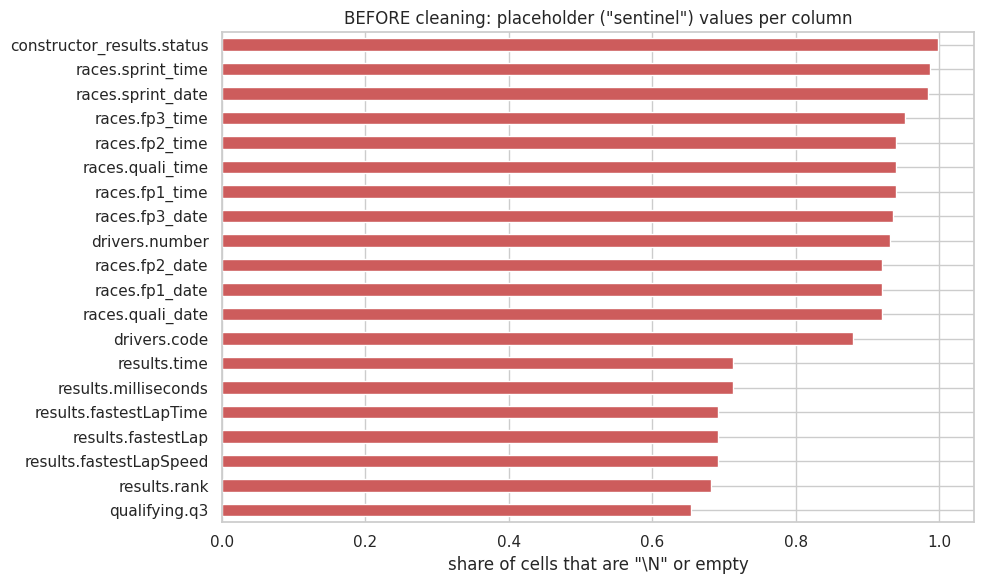

In [10]:
# Share of sentinel values per column (top 20 columns across all tables)
sent_share = pd.concat({t: df.isin(SENTINELS).mean() for t, df in raw.items()}).rename('share')
sent_share = sent_share[sent_share > 0].sort_values(ascending=False)
sent_share.index = [f'{t}.{c}' for t, c in sent_share.index]

fig, ax = plt.subplots(figsize=(10, 6))
sent_share.head(20).sort_values().plot.barh(ax=ax, color='indianred')
ax.set_xlabel('share of cells that are "\\N" or empty'); ax.set_title('BEFORE cleaning: placeholder ("sentinel") values per column')
plt.tight_layout(); plt.show()

In [11]:
# What happens if we read the files naively (pandas defaults)? Numeric columns containing "\N" become text (object).
naive = pd.read_csv(os.path.join(DATA_DIR, 'results.csv'))
naive_types = naive.dtypes.astype(str).rename('naive dtype').to_frame()
naive_types['example values'] = [', '.join(map(str, naive[c].unique()[:4])) for c in naive.columns]
naive_types.loc[['grid', 'position', 'milliseconds', 'fastestLap', 'fastestLapTime', 'fastestLapSpeed']]

,naive dtype,example values
grid,int64,"1, 5, 7, 11"
position,object,"1, 2, 3, 4"
milliseconds,object,"5690616, 5696094, 5698779, 5707797"
fastestLap,object,"39, 41, 58, 43"
fastestLapTime,object,"1:27.452, 1:27.739, 1:28.090, 1:28.603"
fastestLapSpeed,object,"218.300, 217.586, 216.719, 215.464"


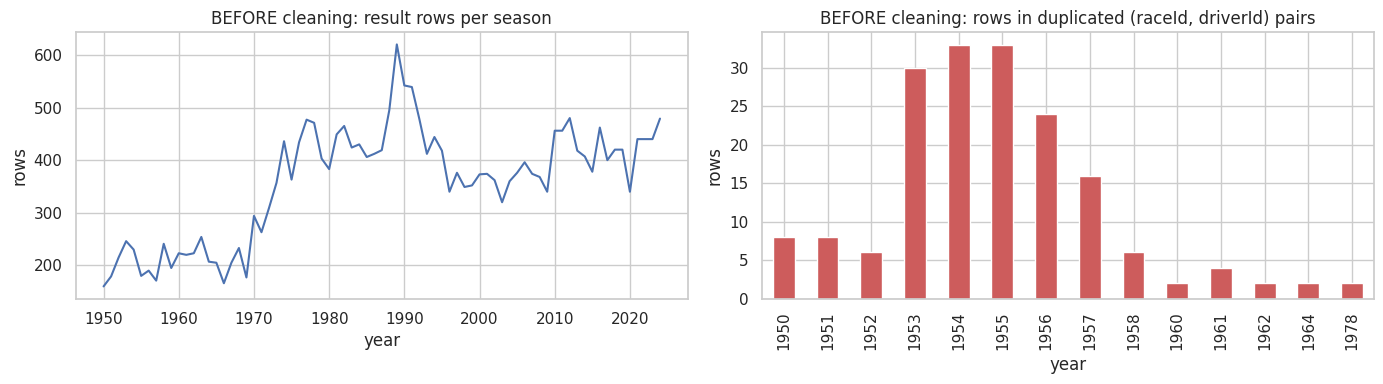

Duplicated rows: 176 | distinct duplicated pairs: 85


In [12]:
# Raw shape of the problem: entries per season and raw duplicate (raceId, driverId) pairs in results
r0 = raw['results'].merge(raw['races'][['raceId', 'year']], on='raceId')
r0['year'] = r0['year'].astype(int)
dup_mask = r0.duplicated(['raceId', 'driverId'], keep=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
r0.groupby('year').size().plot(ax=axes[0])
axes[0].set_title('BEFORE cleaning: result rows per season'); axes[0].set_ylabel('rows')
r0[dup_mask].groupby('year').size().plot.bar(ax=axes[1], color='indianred')
axes[1].set_title('BEFORE cleaning: rows in duplicated (raceId, driverId) pairs'); axes[1].set_ylabel('rows')
plt.tight_layout(); plt.show()
print('Duplicated rows:', int(dup_mask.sum()), '| distinct duplicated pairs:', r0[dup_mask][['raceId', 'driverId']].drop_duplicates().shape[0])

**What the raw audit shows**
- Missing values are encoded as the literal string `\N` (and in `qualifying.q2/q3` also as empty strings). Read naively, numeric columns such as `position`, `milliseconds` or `fastestLapSpeed` become text, so they cannot be used for maths until cleaned.
- Times are stored as text (`"1:27.452"`), dates as text (`"2009-03-29"`).
- `results` contains drivers who appear **more than once in the same race** — all of them in early seasons (shared drives).

## 2. Data cleaning

### 2.1 Sentinels and semantic typing
1. Replace both sentinels (`\N`, empty string) with a real missing value (`NaN`).
2. Convert every column whose non-missing values are all numeric into a numeric type.
3. **Semantic typing**: dates → `datetime`, lap/qualifying/pit-stop times (`"m:ss.sss"`) → numeric **seconds**.

In [13]:
def clean_table(df):
    df = df.replace({s: np.nan for s in SENTINELS})
    for c in df.columns:
        conv = pd.to_numeric(df[c], errors='coerce')
        if conv.notna().sum() == df[c].notna().sum():      # every non-missing value is numeric
            df[c] = conv
    return df

def time_to_seconds(s):
    # '1:27.452' -> 87.452 ; '1:34:50.616' -> 5690.616 ; '26.898' -> 26.898
    if pd.isna(s):
        return np.nan
    try:
        parts = [float(p) for p in str(s).split(':')]
    except ValueError:
        return np.nan
    sec = 0.0
    for p in parts:
        sec = sec * 60 + p
    return sec

clean = {t: clean_table(df.copy()) for t, df in raw.items()}
# lap_times: numeric columns typed directly; the text 'time' column is parsed on a 100,000-row sample only (memory)
clean[BIG] = pd.read_csv(os.path.join(DATA_DIR, f'{BIG}.csv'), usecols=['raceId', 'driverId', 'lap', 'position', 'milliseconds'],
                         na_values=SENTINELS, keep_default_na=False)

# semantic typing
clean['races']['date'] = pd.to_datetime(clean['races']['date'])
for c in ['fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']:
    clean['races'][c] = pd.to_datetime(clean['races'][c])
clean['drivers']['dob'] = pd.to_datetime(clean['drivers']['dob'])
for c in ['q1', 'q2', 'q3']:
    clean['qualifying'][c + '_sec'] = clean['qualifying'][c].map(time_to_seconds)
clean['results']['fastestLapTime_sec'] = clean['results']['fastestLapTime'].map(time_to_seconds)
clean['sprint_results']['fastestLapTime_sec'] = clean['sprint_results']['fastestLapTime'].map(time_to_seconds)
clean['pit_stops']['duration_sec'] = clean['pit_stops']['duration'].map(time_to_seconds)

# sanity check of the time parser: converted lap times agree with the milliseconds column (100,000-row sample)
lt = pd.read_csv(os.path.join(DATA_DIR, f'{BIG}.csv'), usecols=['time', 'milliseconds'], nrows=100_000, dtype={'time': str})
lt['time_sec'] = lt['time'].map(time_to_seconds)
print('max |time_sec*1000 - milliseconds| in lap_times sample:', float((lt['time_sec'] * 1000 - lt['milliseconds']).abs().max()), 'ms')

def numeric_stored_as_text(tables):
    # columns whose real values are all numbers but which are stored as text
    n = 0
    for df in tables.values():
        for c in df.columns:
            if pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_datetime64_any_dtype(df[c]):
                continue
            vals = df[c][~df[c].isin(SENTINELS)].dropna()
            if len(vals) and pd.to_numeric(vals, errors='coerce').notna().all():
                n += 1
    return n

# keep the raw-data statistics needed for the before/after table, then free the big raw text copies (1 GB sessions)
RAW_STATS = {'sentinels': int(sum((df == '\\N').sum().sum() + (df == '').sum().sum() for df in raw.values())
                                 + big_row[r'"\N" cells'] + big_row['empty-string cells']),
             'numeric_as_text': numeric_stored_as_text(raw) + int(big_numeric.sum())}
del lt
gc.collect()

typed = pd.DataFrame({'raw dtype': [raw['results'][c].dtype for c in ['grid', 'position', 'milliseconds', 'fastestLapTime']] +
                                   [raw['races']['date'].dtype, raw['qualifying']['q1'].dtype],
                      'clean dtype': [clean['results'][c].dtype for c in ['grid', 'position', 'milliseconds', 'fastestLapTime_sec']] +
                                     [clean['races']['date'].dtype, clean['qualifying']['q1_sec'].dtype]},
                     index=['results.grid', 'results.position', 'results.milliseconds', 'results.fastestLapTime',
                            'races.date', 'qualifying.q1']).astype(str)
typed

max |time_sec*1000 - milliseconds| in lap_times sample: 2.9103830456733704e-11 ms


,raw dtype,clean dtype
results.grid,object,int64
results.position,object,float64
results.milliseconds,object,float64
results.fastestLapTime,object,float64
races.date,object,datetime64[ns]
qualifying.q1,object,float64


Q1 times above 150 s (implausible / data-entry outliers, kept but clipped in the plot): 4


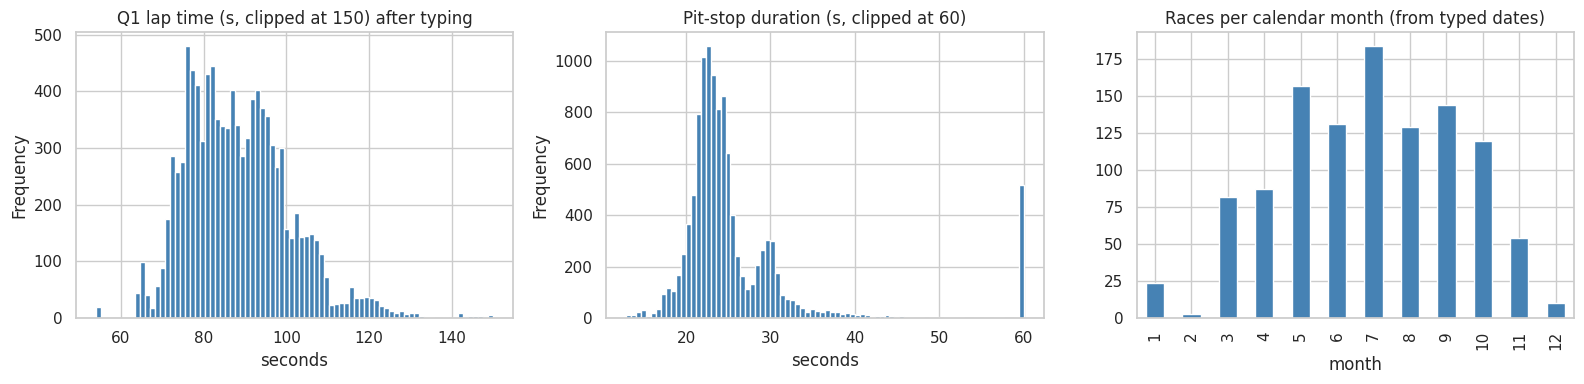

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
q1s = clean['qualifying']['q1_sec']
q1s.clip(upper=150).plot.hist(bins=80, ax=axes[0], color='steelblue')
axes[0].set_title('Q1 lap time (s, clipped at 150) after typing'); axes[0].set_xlabel('seconds')
print(f'Q1 times above 150 s (implausible / data-entry outliers, kept but clipped in the plot): {int((q1s > 150).sum())}')
clean['pit_stops']['duration_sec'].clip(upper=60).plot.hist(bins=80, ax=axes[1], color='steelblue')
axes[1].set_title('Pit-stop duration (s, clipped at 60)'); axes[1].set_xlabel('seconds')
clean['races'].groupby(clean['races']['date'].dt.month).size().plot.bar(ax=axes[2], color='steelblue')
axes[2].set_title('Races per calendar month (from typed dates)'); axes[2].set_xlabel('month')
plt.tight_layout(); plt.show()

Typing makes the values usable: lap times become a continuous distribution (most Q1 laps 70–110 s; the long tail is wet sessions and long tracks), pit-stop durations show the normal ~20–30 s pit-lane time with rare long stops (repairs, red flags), and dates allow ordering races in time — which the leakage-safe features in Section 4 depend on.

### 2.2 Grain: exactly one row per (raceId, driverId)

Every row of the modeling table is one prediction, so `(raceId, driverId)` must be unique.

In [15]:
res = clean['results'].merge(clean['races'][['raceId', 'year']], on='raceId').merge(clean['status'], on='statusId')
dups = res[res.duplicated(['raceId', 'driverId'], keep=False)].sort_values(['raceId', 'driverId', 'grid'])
print('duplicated rows:', len(dups), '| duplicated pairs:', dups.groupby(['raceId', 'driverId']).ngroups,
      '| seasons:', sorted(dups['year'].unique()))
dups[dups['raceId'] == 792][['raceId', 'year', 'driverId', 'constructorId', 'number', 'grid', 'positionOrder', 'laps', 'status', 'points']]

duplicated rows: 176 | duplicated pairs: 85 | seasons: [np.int64(1950), np.int64(1951), np.int64(1952), np.int64(1953), np.int64(1954), np.int64(1955), np.int64(1956), np.int64(1957), np.int64(1958), np.int64(1960), np.int64(1961), np.int64(1962), np.int64(1964), np.int64(1978)]


,raceId,year,driverId,constructorId,number,grid,positionOrder,laps,status,points
20244,792,1955,427,6,12.0,1,2,96,Finished,2.00
20245,792,1955,427,6,10.0,5,3,94,+2 Laps,1.33
19066,792,1955,427,6,14.0,14,11,36,Engine,0.00
19068,792,1955,475,131,6.0,8,13,29,Fuel system,0.00
20248,792,1955,475,131,8.0,10,4,94,+2 Laps,1.00
19076,792,1955,496,105,24.0,13,21,1,Accident,0.00
20255,792,1955,496,105,26.0,20,9,54,Fuel pressure,0.00
19061,792,1955,501,105,28.0,7,6,88,+8 Laps,0.00
20251,792,1955,501,105,22.0,18,7,83,+13 Laps,0.00
20254,792,1955,501,105,26.0,20,9,54,Fuel pressure,0.00


In race 792 (1955 Argentine GP, held in extreme heat) drivers swapped cars mid-race, so the same driver is listed for up to three cars and the shared points (e.g. 1.33) were split between them.

**Rule: keep the entry the driver started the race in, decided with pre-race information only.**
1. prefer rows with a real grid slot (`grid > 0`);
2. among those, the best (lowest) grid position — the driver's primary entry;
3. ties → the lowest `resultId` (first entry listed).

**Why this rule:** our prediction is made *before the race*, about the car the driver lines up in. Choosing the row by its result (e.g. "keep the best finish" or "most laps") would select rows using race outcomes — a subtle form of leakage. The rule is deterministic and reproducible.

In [16]:
def dedupe_results(df):
    df = df.copy()
    df['_has_slot'] = (df['grid'] > 0).astype(int)
    df['_grid_key'] = df['grid'].where(df['grid'] > 0, 999)
    df = df.sort_values(['raceId', 'driverId', '_has_slot', '_grid_key', 'resultId'],
                        ascending=[True, True, False, True, True])
    return df.drop_duplicates(['raceId', 'driverId'], keep='first').drop(columns=['_has_slot', '_grid_key'])

results_unique = dedupe_results(clean['results'])
assert not results_unique.duplicated(['raceId', 'driverId']).any()

# sensitivity: how many podium labels would differ under an outcome-based rule ("keep best finish")?
alt = clean['results'].sort_values(['raceId', 'driverId', 'positionOrder']).drop_duplicates(['raceId', 'driverId'])
cmp_ = results_unique.merge(alt, on=['raceId', 'driverId'], suffixes=('', '_alt'))
dup_pairs = dups[['raceId', 'driverId']].drop_duplicates()
cmp_ = cmp_.merge(dup_pairs, on=['raceId', 'driverId'])
diff = ((cmp_['positionOrder'] <= 3) != (cmp_['positionOrder_alt'] <= 3)).sum()
print(f"results: {len(clean['results'])} -> {len(results_unique)} rows ({len(clean['results']) - len(results_unique)} removed)")
print(f'podium label differs between our rule and "keep best finish" for {diff} of {len(cmp_)} duplicated pairs')
print('qualifying (raceId, driverId) duplicates:', int(clean['qualifying'].duplicated(['raceId', 'driverId']).sum()))

results: 26759 -> 26668 rows (91 removed)
podium label differs between our rule and "keep best finish" for 17 of 85 duplicated pairs
qualifying (raceId, driverId) duplicates: 0


All duplicates are from 1950–1978. The modeling period chosen in Section 2.4 starts in 2003, so the rule cannot influence the model; it matters for the historical analyses in Section 3 (Q2 uses all seasons). The outcome-based alternative would change a handful of podium labels — exactly the bias we avoid by deciding with grid data only.

### 2.3 Primary keys and foreign keys

- **Primary key (PK)**: the column(s) that identify a row → must be unique and non-null.
- **Foreign key (FK)**: a column that points to a PK in another table → every value must exist in the parent table.

In [17]:
tables_for_keys = dict(clean)
tables_for_keys['results'] = results_unique

PKS = {'circuits': ['circuitId'], 'constructors': ['constructorId'], 'drivers': ['driverId'], 'races': ['raceId'],
       'seasons': ['year'], 'status': ['statusId'], 'results': ['resultId'], 'qualifying': ['qualifyId'],
       'driver_standings': ['driverStandingsId'], 'constructor_standings': ['constructorStandingsId'],
       'constructor_results': ['constructorResultsId'], 'sprint_results': ['resultId'],
       'lap_times': ['raceId', 'driverId', 'lap'], 'pit_stops': ['raceId', 'driverId', 'stop']}
pk_report = pd.DataFrame([{'table': t, 'primary key': '+'.join(k),
                           'null keys': int(tables_for_keys[t][k].isna().any(axis=1).sum()),
                           'duplicate keys': int(tables_for_keys[t].duplicated(k).sum())} for t, k in PKS.items()])

FKS = [('races', 'circuitId', 'circuits', 'circuitId'), ('races', 'year', 'seasons', 'year'),
       ('results', 'raceId', 'races', 'raceId'), ('results', 'driverId', 'drivers', 'driverId'),
       ('results', 'constructorId', 'constructors', 'constructorId'), ('results', 'statusId', 'status', 'statusId'),
       ('qualifying', 'raceId', 'races', 'raceId'), ('qualifying', 'driverId', 'drivers', 'driverId'),
       ('qualifying', 'constructorId', 'constructors', 'constructorId'),
       ('driver_standings', 'raceId', 'races', 'raceId'), ('driver_standings', 'driverId', 'drivers', 'driverId'),
       ('constructor_standings', 'raceId', 'races', 'raceId'), ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
       ('constructor_results', 'raceId', 'races', 'raceId'), ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
       ('lap_times', 'raceId', 'races', 'raceId'), ('lap_times', 'driverId', 'drivers', 'driverId'),
       ('pit_stops', 'raceId', 'races', 'raceId'), ('pit_stops', 'driverId', 'drivers', 'driverId'),
       ('sprint_results', 'raceId', 'races', 'raceId'), ('sprint_results', 'driverId', 'drivers', 'driverId'),
       ('sprint_results', 'constructorId', 'constructors', 'constructorId'), ('sprint_results', 'statusId', 'status', 'statusId')]
fk_report = pd.DataFrame([{'foreign key': f'{c}.{col}', 'references': f'{p}.{pcol}',
                           'values': int(tables_for_keys[c][col].notna().sum()),
                           'orphans (missing in parent)': int((~tables_for_keys[c][col].dropna().isin(tables_for_keys[p][pcol])).sum())}
                          for c, col, p, pcol in FKS])
fk_report['reconciles'] = fk_report['orphans (missing in parent)'] == 0
display(pk_report)
display(fk_report)

,table,primary key,null keys,duplicate keys
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,drivers,driverId,0,0
3,races,raceId,0,0
4,seasons,year,0,0
5,status,statusId,0,0
6,results,resultId,0,0
7,qualifying,qualifyId,0,0
8,driver_standings,driverStandingsId,0,0
9,constructor_standings,constructorStandingsId,0,0


,foreign key,references,values,orphans (missing in parent),reconciles
0,races.circuitId,circuits.circuitId,1125,0,True
1,races.year,seasons.year,1125,0,True
2,results.raceId,races.raceId,26668,0,True
3,results.driverId,drivers.driverId,26668,0,True
4,results.constructorId,constructors.constructorId,26668,0,True
5,results.statusId,status.statusId,26668,0,True
6,qualifying.raceId,races.raceId,10494,0,True
7,qualifying.driverId,drivers.driverId,10494,0,True
8,qualifying.constructorId,constructors.constructorId,10494,0,True
9,driver_standings.raceId,races.raceId,34863,0,True


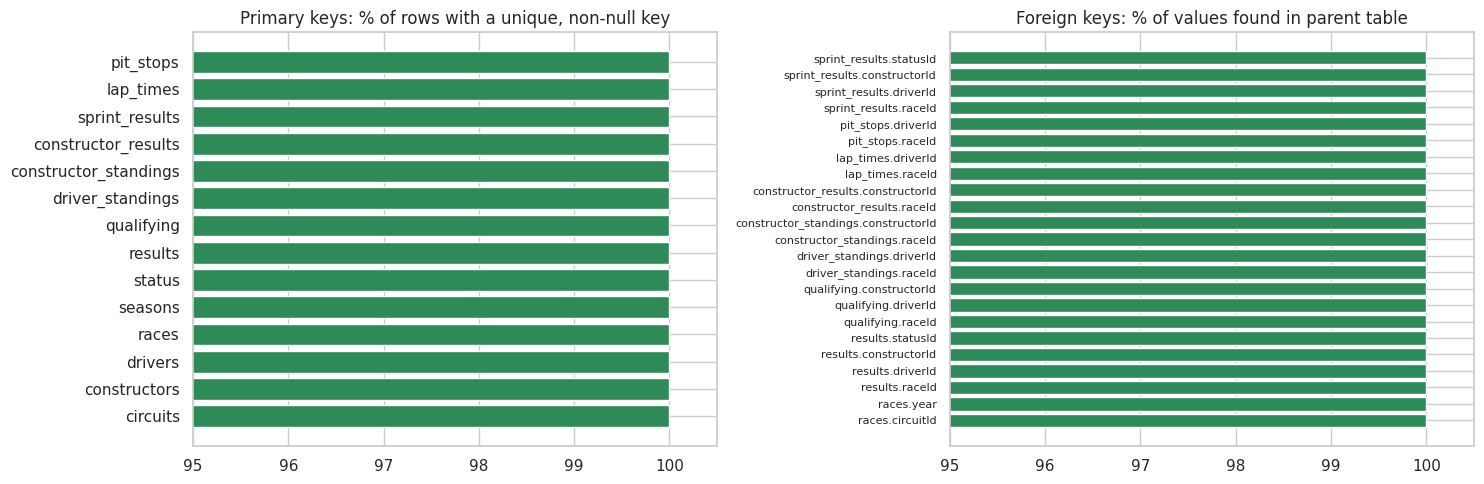

All PKs valid: True | All FKs reconcile: True


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
pk_valid = 100 * (1 - (pk_report['null keys'] + pk_report['duplicate keys']) /
                  pk_report['table'].map(lambda t: len(tables_for_keys[t])))
axes[0].barh(pk_report['table'], pk_valid, color=np.where(pk_valid == 100, 'seagreen', 'indianred'))
axes[0].set_xlim(95, 100.5); axes[0].set_title('Primary keys: % of rows with a unique, non-null key')
match = 100 * (1 - fk_report['orphans (missing in parent)'] / fk_report['values'])
axes[1].barh(fk_report['foreign key'], match, color=np.where(fk_report['reconciles'], 'seagreen', 'indianred'))
axes[1].set_xlim(95, 100.5); axes[1].set_title('Foreign keys: % of values found in parent table')
axes[1].tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()
print('All PKs valid:', bool((pk_report[['null keys', 'duplicate keys']] == 0).all().all()),
      '| All FKs reconcile:', bool(fk_report['reconciles'].all()))

### 2.4 EDA after cleaning

Now that values are typed and the grain is fixed we can explore the data properly — and see what the cleaning changed.

In [19]:
cleaned_tables = dict(clean); cleaned_tables['results'] = results_unique
before_after = pd.DataFrame({
    'before cleaning': [len(raw['results']), int(raw['results'].duplicated(['raceId', 'driverId']).sum()),
                        RAW_STATS['sentinels'], RAW_STATS['numeric_as_text'], 0],
    'after cleaning': [len(results_unique), int(results_unique.duplicated(['raceId', 'driverId']).sum()),
                       int(sum(cleaned_tables[t].isin(SENTINELS).sum().sum() for t in TABLES)),
                       numeric_stored_as_text(cleaned_tables),
                       int(sum(cleaned_tables[t].select_dtypes(include='datetime').shape[1] for t in TABLES))]},
    index=['result rows', 'extra duplicate (raceId, driverId) rows', 'sentinel strings',
           'numeric columns stored as text', 'date columns typed as datetime'])
# lap_times / pit_stops were only needed for typing and key checks -> release them (memory)
for d in (clean, cleaned_tables, tables_for_keys):
    d.pop('lap_times', None)
del cleaned_tables, tables_for_keys, naive, r0; gc.collect()
before_after

,before cleaning,after cleaning
result rows,26759,26668
"extra duplicate (raceId, driverId) rows",91,0
sentinel strings,160144,0
numeric columns stored as text,73,0
date columns typed as datetime,0,7


In [20]:
# Build an enriched entry table (one row per driver per race) with multi-hop joins
races = clean['races'][['raceId', 'year', 'round', 'circuitId', 'name', 'date']].rename(columns={'name': 'race_name'})
circuits = clean['circuits'][['circuitId', 'name', 'country']].rename(columns={'name': 'circuit_name', 'country': 'circuit_country'})
drivers = clean['drivers'][['driverId', 'driverRef', 'forename', 'surname', 'dob', 'nationality']]
constructors = clean['constructors'][['constructorId', 'name']].rename(columns={'name': 'constructor_name'})
quali = clean['qualifying'][['raceId', 'driverId', 'position', 'q1_sec', 'q2_sec', 'q3_sec']].rename(columns={'position': 'quali_pos'})

NON_START = {'Did not qualify', 'Did not prequalify', 'Withdrew', '107% Rule'}
entries = (results_unique.merge(races, on='raceId').merge(circuits, on='circuitId')
           .merge(clean['status'], on='statusId').merge(drivers, on='driverId')
           .merge(constructors, on='constructorId').merge(quali, on=['raceId', 'driverId'], how='left'))
entries['podium'] = (entries['positionOrder'] <= 3).astype(int)
entries['started'] = ~entries['status'].isin(NON_START)
entries['circuit_country'] = entries['circuit_country'].replace({'United States': 'USA'})
print(entries.shape, '| non-starters (DNQ/DNPQ/withdrew):', int((~entries['started']).sum()))

(26668, 39) | non-starters (DNQ/DNPQ/withdrew): 1610


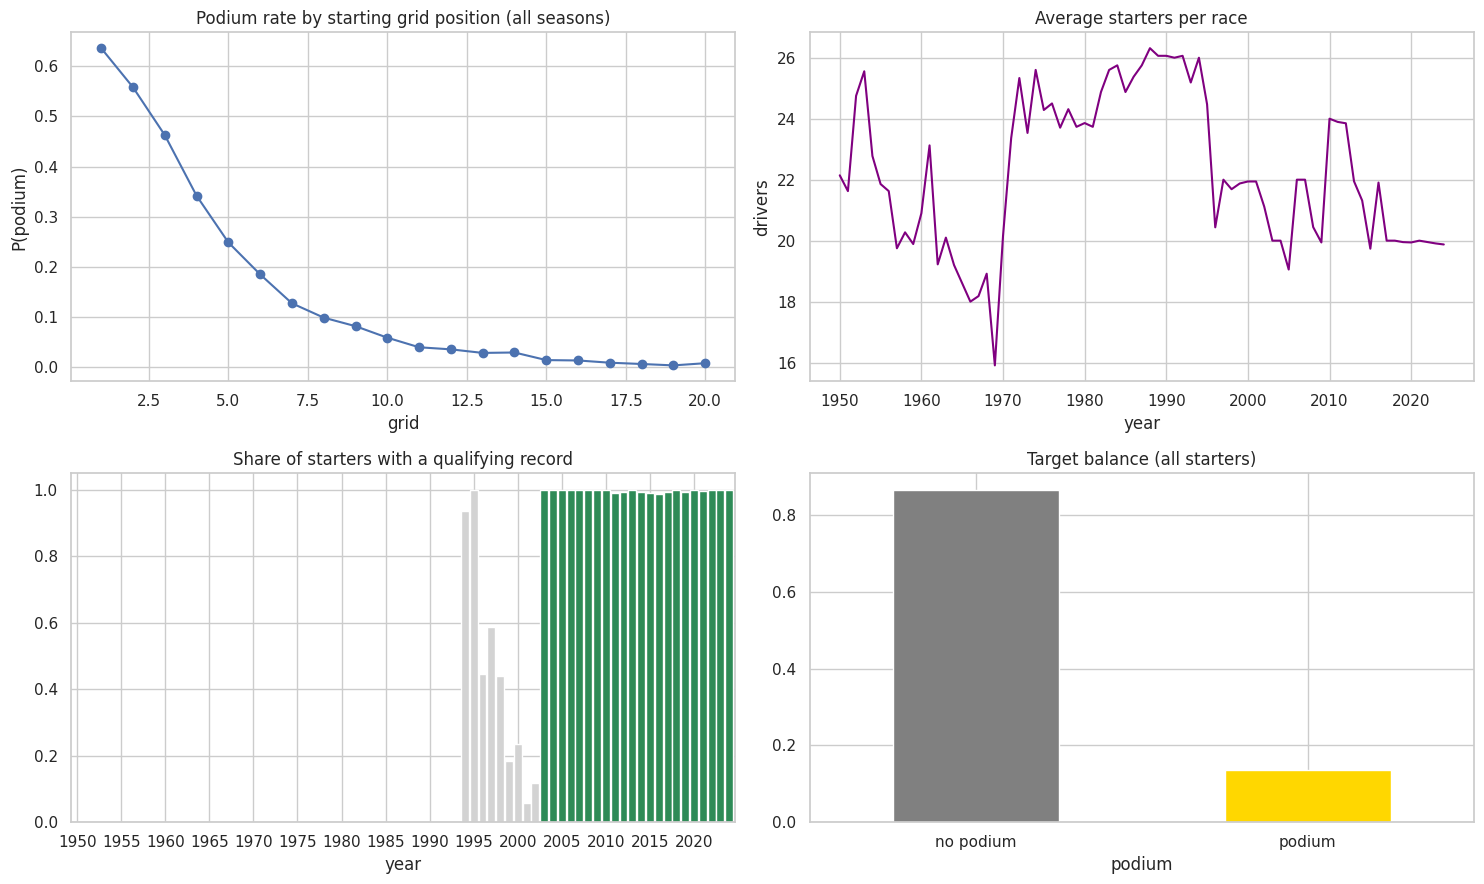

{1990: 0.0, 1991: 0.0, 1992: 0.0, 1993: 0.0, 1994: 0.94, 1995: 1.0, 1996: 0.45, 1997: 0.59, 1998: 0.44, 1999: 0.19, 2000: 0.24, 2001: 0.06, 2002: 0.12, 2003: 1.0, 2004: 1.0, 2005: 1.0, 2006: 1.0, 2007: 1.0, 2008: 1.0, 2009: 1.0, 2010: 1.0, 2011: 0.99, 2012: 0.99, 2013: 1.0, 2014: 1.0, 2015: 0.99, 2016: 0.99, 2017: 1.0, 2018: 1.0, 2019: 1.0, 2020: 1.0, 2021: 1.0, 2022: 1.0, 2023: 1.0, 2024: 1.0}


In [21]:
st = entries[entries['started']]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

rate_by_grid = st[st['grid'].between(1, 20)].groupby('grid')['podium'].mean()
rate_by_grid.plot(marker='o', ax=axes[0, 0]); axes[0, 0].set_title('Podium rate by starting grid position (all seasons)')
axes[0, 0].set_xlabel('grid'); axes[0, 0].set_ylabel('P(podium)')

per_year = st.groupby('year').agg(field=('driverId', 'size'), races=('raceId', 'nunique'))
(per_year['field'] / per_year['races']).plot(ax=axes[0, 1], color='purple')
axes[0, 1].set_title('Average starters per race'); axes[0, 1].set_ylabel('drivers')

cov = st.groupby('year')['quali_pos'].apply(lambda s: s.notna().mean())
cov.plot.bar(ax=axes[1, 0], color=np.where(cov.index >= 2003, 'seagreen', 'lightgray'), width=0.9)
axes[1, 0].set_title('Share of starters with a qualifying record'); axes[1, 0].set_xticks(range(0, len(cov), 5))
axes[1, 0].set_xticklabels(cov.index[::5], rotation=0)

st['podium'].value_counts(normalize=True).rename({0: 'no podium', 1: 'podium'}).plot.bar(ax=axes[1, 1], color=['gray', 'gold'])
axes[1, 1].set_title('Target balance (all starters)'); axes[1, 1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
print(cov[cov.index >= 1990].round(2).to_dict())

**Findings after cleaning (and the decisions they drive)**
- **Grid is a very strong signal:** podium probability falls steeply from pole to the midfield → grid/qualifying features are the core of the model.
- **Field size changed a lot** (30+ starters in the 1950s, ~20 today) → the base chance of a podium differs by era, so we work within a consistent period.
- **Qualifying coverage drift:** before 1994 there is no qualifying data at all, 1996–2002 coverage is patchy, and **from 2003 coverage is ~100 %**. → **Modeling period = 2003–2024.** (Hypothesis-driven choice: using older seasons would mean a qualifying feature that is missing for structural, not random, reasons.)
- **Class imbalance:** only ~13 % of starters reach the podium → accuracy is misleading; we evaluate with PR-AUC, ROC-AUC and F1 (Section 6).

## 3. Data-engineering questions

Each answer uses multi-hop joins (`results` → `races` → `circuits`, + `qualifying`, `drivers`, `status`, `constructors`), states its **grain**, its **missingness**, and its relation to the **pre-race cutoff**.

### Q1. Which circuits convert a front-row start into a podium most often — and does the ranking change after 2014?

- **Grain:** one row per front-row starter per race (2 per race).
- **Front row by qualifying** (`qualifying.position ≤ 2`) vs **front row by grid** (`results.grid ≤ 2`) — they differ when grid penalties move a driver.
- **Period:** 2003–2013 vs 2014–2024 (11 seasons each; qualifying coverage is complete in both, so the comparison is like-for-like).
- **Pre-race cutoff:** both qualifying position and grid are known before the race.
- Circuits need **≥ 8 front-row starts in each era** (≥ 4 races) — rates from 2 races would be noise.

In [22]:
q1df = entries[(entries['year'] >= 2003) & entries['started']].copy()
q1df['era'] = np.where(q1df['year'] < 2014, '2003-2013', '2014-2024')

def front_row_conversion(df, col):
    fr = df[df[col].between(1, 2)]
    t = fr.groupby(['circuit_name', 'era'])['podium'].agg(starts='size', podiums='sum').reset_index()
    t['conversion'] = t['podiums'] / t['starts']
    wide = t.pivot(index='circuit_name', columns='era', values=['conversion', 'starts'])
    ok = (wide['starts'] >= 8).all(axis=1)
    return wide['conversion'][ok]

conv_q = front_row_conversion(q1df, 'quali_pos')
conv_g = front_row_conversion(q1df, 'grid')

# where do qualifying and grid disagree? (grid penalties / pit-lane starts)
pen = q1df[q1df['quali_pos'].between(1, 2) & ~q1df['grid'].between(1, 2)]
promo = q1df[~q1df['quali_pos'].between(1, 2) & q1df['grid'].between(1, 2)]
print(f'Front-row qualifiers who did NOT start from the front row: {len(pen)} (podium rate {pen.podium.mean():.2f})')
print(f'Drivers promoted onto the front row by others\' penalties: {len(promo)} (podium rate {promo.podium.mean():.2f})')
print(f'Overall front-row conversion — by qualifying: {q1df[q1df.quali_pos.between(1,2)].podium.mean():.3f}, '
      f'by grid: {q1df[q1df.grid.between(1,2)].podium.mean():.3f}')

rho, p = spearmanr(conv_q['2003-2013'], conv_q['2014-2024'])
print(f'Circuits compared: {len(conv_q)} | Spearman rank correlation between eras (qualifying-based): {rho:.2f} (p={p:.2f})')
q1_table = conv_q.copy()
q1_table['rank 2003-2013'] = q1_table['2003-2013'].rank(ascending=False, method='min').astype(int)
q1_table['rank 2014-2024'] = q1_table['2014-2024'].rank(ascending=False, method='min').astype(int)
q1_table['grid-based 2014-2024'] = conv_g['2014-2024']
q1_table.sort_values('2014-2024', ascending=False).round(2)

Front-row qualifiers who did NOT start from the front row: 38 (podium rate 0.29)
Drivers promoted onto the front row by others' penalties: 36 (podium rate 0.64)
Overall front-row conversion — by qualifying: 0.708, by grid: 0.724
Circuits compared: 17 | Spearman rank correlation between eras (qualifying-based): 0.45 (p=0.07)


era,2003-2013,2014-2024,rank 2003-2013,rank 2014-2024,grid-based 2014-2024
circuit_name,,,,,
Suzuka Circuit,0.72,0.89,3,1,0.89
Circuit de Monaco,0.68,0.85,7,2,0.85
Yas Marina Circuit,0.60,0.82,12,3,0.86
Circuit de Spa-Francorchamps,0.72,0.82,3,3,0.82
Circuit de Barcelona-Catalunya,0.64,0.82,9,3,0.82
Shanghai International Circuit,0.70,0.79,6,6,0.79
Sepang International Circuit,0.64,0.75,9,7,NaN
Silverstone Circuit,0.77,0.75,1,7,0.75
Autodromo Nazionale di Monza,0.73,0.73,2,9,0.73


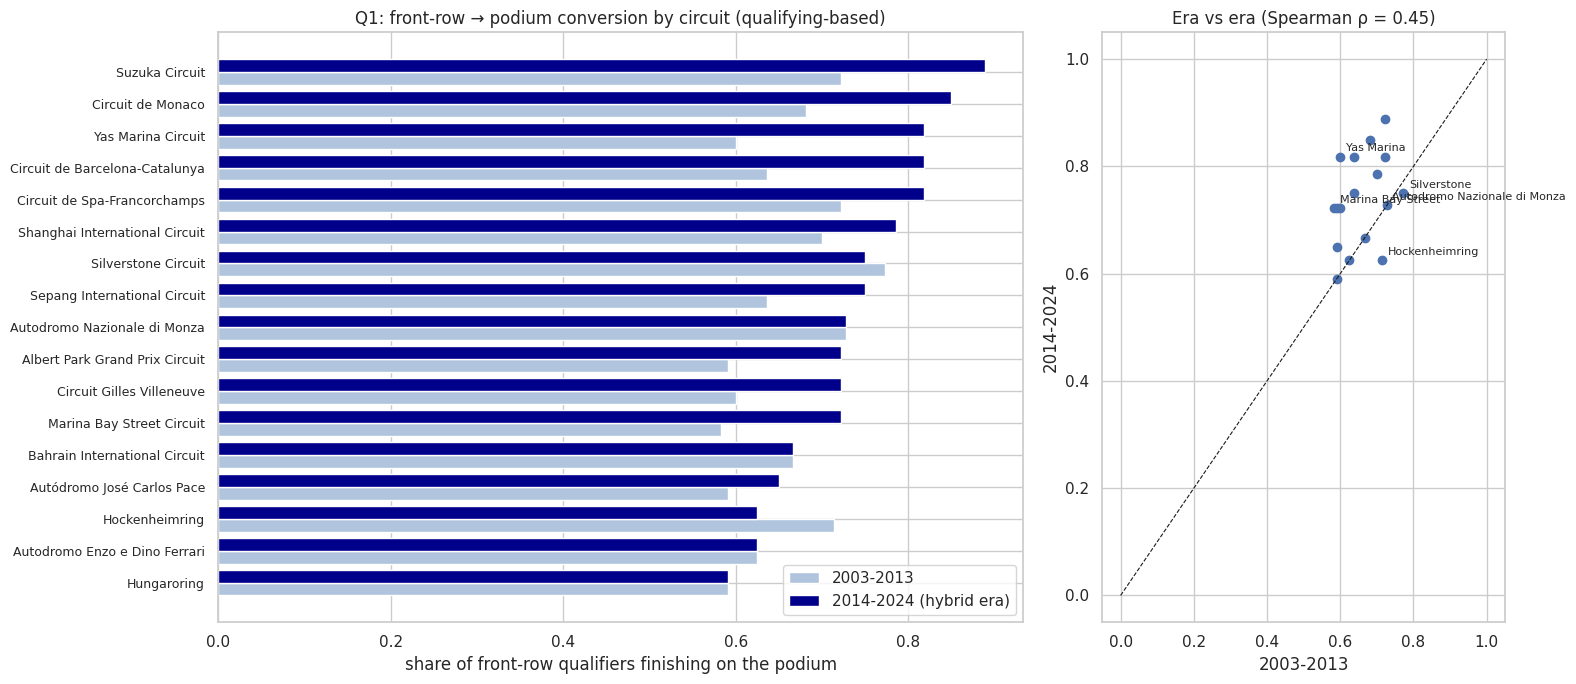

In [23]:
plot_df = conv_q.sort_values('2014-2024')
fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [2, 1]})
y = np.arange(len(plot_df))
axes[0].barh(y - 0.2, plot_df['2003-2013'], height=0.4, label='2003-2013', color='lightsteelblue')
axes[0].barh(y + 0.2, plot_df['2014-2024'], height=0.4, label='2014-2024 (hybrid era)', color='darkblue')
axes[0].set_yticks(y); axes[0].set_yticklabels(plot_df.index, fontsize=9)
axes[0].set_xlabel('share of front-row qualifiers finishing on the podium'); axes[0].legend()
axes[0].set_title('Q1: front-row → podium conversion by circuit (qualifying-based)')

axes[1].scatter(conv_q['2003-2013'], conv_q['2014-2024'])
rank_shift = (q1_table['rank 2003-2013'] - q1_table['rank 2014-2024']).abs().sort_values(ascending=False)
for c in rank_shift.index[:5]:                                   # label only the biggest rank changes
    axes[1].annotate(c.replace(' Circuit', '').replace(' International', ''), (conv_q.loc[c, '2003-2013'], conv_q.loc[c, '2014-2024']),
                     fontsize=8, xytext=(4, 4), textcoords='offset points')
axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[1].set_xlabel('2003-2013'); axes[1].set_ylabel('2014-2024'); axes[1].set_title(f'Era vs era (Spearman ρ = {rho:.2f})')
plt.tight_layout(); plt.show()

**Answer Q1.**
- **Most reliable circuits in the hybrid era (2014–2024):** Suzuka (89 % of front-row qualifiers reached the podium), Monaco (85 %), then Spa, Barcelona and Yas Marina (82 %). In 2003–2013 the top three were Silverstone (77 %), Monza (73 %) and Suzuka/Spa (72 %).
- **Overall** about 7 in 10 front-row qualifiers finish on the podium (70.8 % by qualifying, 72.4 % by grid), and conversion rose at most circuits after 2014, when one dominant car (Mercedes, later Red Bull) usually locked out the front row.
- **Does the ranking change?** Yes, partly: the Spearman rank correlation between the eras is only **0.45** (p ≈ 0.07, 17 circuits). Silverstone fell from 1st to 7th, Yas Marina rose from 12th to 3rd, Hockenheim fell from 5th to 15th. A circuit's "front-row advantage" depends a lot on which cars dominated.
- **Qualifying vs grid:** 38 front-row qualifiers did **not** start from the front row (grid penalties); only 29 % of them reached the podium. 36 drivers were promoted onto the front row by others' penalties and 64 % of them reached the podium. The grid-based column shows conversion once penalties are applied (e.g. Interlagos 65 % → 79 %).
- **Grain / missingness:** one row per front-row starter; qualifying is complete for 2003–2024; circuits with < 8 front-row starts in either era are excluded (e.g. new circuits like Jeddah or Las Vegas).

### Q2. Do drivers podium more often at home, after controlling for starting position?

- **Home race:** the driver's nationality (`drivers.nationality`, e.g. *British*) maps to the circuit's country (`circuits.country`, e.g. *UK*) via `races`.
- **Grain:** one row per starter per race, **all seasons** (grid is available in every era).
- **Population:** only drivers from countries that have hosted a Grand Prix (others can never race at home, so comparing them would mix different groups).
- **Control for starting position:** compare home vs away *within the same grid band*, then a logistic regression `podium ~ home + grid band (+ era)`.
- **Pre-race cutoff:** nationality, circuit and grid are all known before the race.

In [24]:
import statsmodels.formula.api as smf          # imported here, not at the top, to keep memory low

NAT2COUNTRY = {'American': 'USA', 'American-Italian': 'USA', 'Argentine': 'Argentina', 'Argentine-Italian': 'Argentina',
               'Argentinian': 'Argentina', 'Australian': 'Australia', 'Austrian': 'Austria', 'Belgian': 'Belgium',
               'Brazilian': 'Brazil', 'British': 'UK', 'Canadian': 'Canada', 'Chinese': 'China', 'Dutch': 'Netherlands',
               'East German': 'Germany', 'German': 'Germany', 'French': 'France', 'Hungarian': 'Hungary', 'Indian': 'India',
               'Italian': 'Italy', 'Japanese': 'Japan', 'Malaysian': 'Malaysia', 'Mexican': 'Mexico', 'Monegasque': 'Monaco',
               'Portuguese': 'Portugal', 'Russian': 'Russia', 'South African': 'South Africa', 'Spanish': 'Spain',
               'Swedish': 'Sweden', 'Swiss': 'Switzerland'}
entries['driver_country'] = entries['nationality'].str.strip().map(NAT2COUNTRY)
entries['home_race'] = (entries['driver_country'] == entries['circuit_country']).astype(int)

hosts = set(entries['circuit_country'])
q2df = entries[entries['started'] & (entries['grid'] > 0) & entries['driver_country'].isin(hosts)].copy()
q2df['grid_band'] = pd.cut(q2df['grid'], [0, 1, 3, 6, 10, 100], labels=['P1', 'P2-3', 'P4-6', 'P7-10', 'P11+'])
q2df['era'] = pd.cut(q2df['year'], [1949, 1979, 2002, 2024], labels=['1950-79', '1980-2002', '2003-24'])

strat = q2df.groupby(['grid_band', 'home_race'], observed=True)['podium'].agg(['mean', 'size']).unstack()
strat.columns = ['away rate', 'home rate', 'away n', 'home n']
strat['difference (home - away)'] = strat['home rate'] - strat['away rate']
w = strat['home n'] / strat['home n'].sum()
adjusted = (w * strat['difference (home - away)']).sum()
print(f'Rows: {len(q2df)} | home rows: {int(q2df.home_race.sum())}')
print(f'Raw podium rate: home {q2df[q2df.home_race==1].podium.mean():.3f} vs away {q2df[q2df.home_race==0].podium.mean():.3f}')
print(f'Grid-adjusted difference (weighted by home rows per band): {adjusted:+.3f}')

logit = smf.logit('podium ~ home_race + C(grid_band) + C(era)', data=q2df.assign(grid_band=q2df.grid_band.astype(str), era=q2df.era.astype(str))).fit(disp=0)
or_ = np.exp(logit.params['home_race']); ci = np.exp(logit.conf_int().loc['home_race'])
print(f'Logistic regression: odds ratio for home = {or_:.2f} (95% CI {ci[0]:.2f}-{ci[1]:.2f}), p = {logit.pvalues["home_race"]:.3f}')
strat.round(3)

Rows: 22602 | home rows: 2312
Raw podium rate: home 0.112 vs away 0.136
Grid-adjusted difference (weighted by home rows per band): -0.006
Logistic regression: odds ratio for home = 0.92 (95% CI 0.78-1.08), p = 0.298


,away rate,home rate,away n,home n,difference (home - away)
grid_band,,,,,
P1,0.649,0.558,948,95,-0.091
P2-3,0.513,0.517,1817,172,0.004
P4-6,0.259,0.240,2707,263,-0.020
P7-10,0.089,0.085,3662,386,-0.004
P11+,0.016,0.016,11156,1396,-0.000


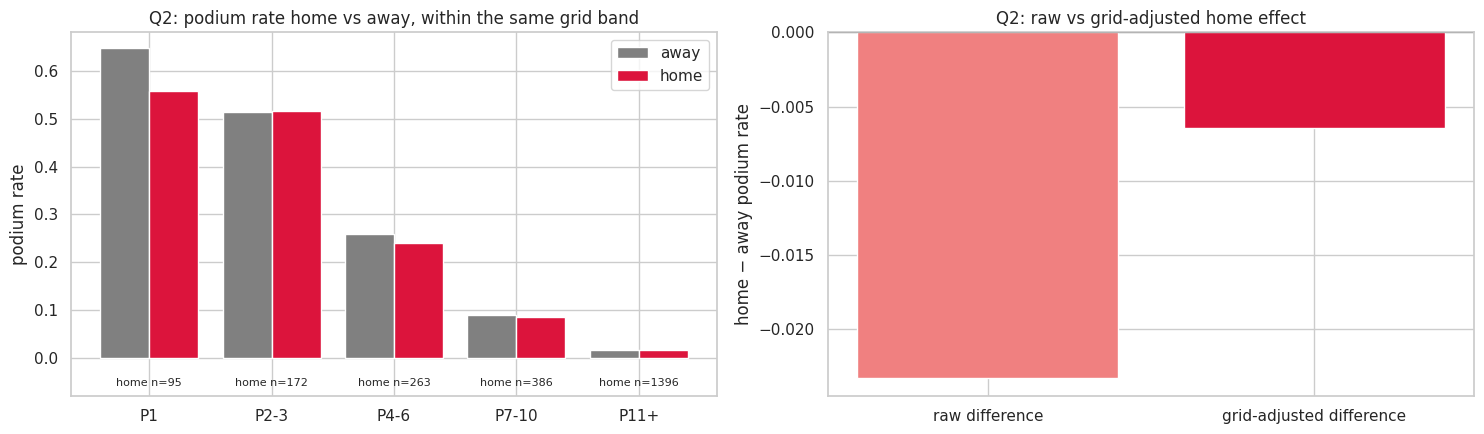

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(strat))
axes[0].bar(x - 0.2, strat['away rate'], 0.4, label='away', color='gray')
axes[0].bar(x + 0.2, strat['home rate'], 0.4, label='home', color='crimson')
axes[0].set_xticks(x); axes[0].set_xticklabels(strat.index); axes[0].set_ylabel('podium rate'); axes[0].legend()
axes[0].set_title('Q2: podium rate home vs away, within the same grid band')
for i, (n1, n0) in enumerate(zip(strat['home n'], strat['away n'])):
    axes[0].text(i, -0.06, f'home n={int(n1)}', ha='center', fontsize=8)
axes[0].set_ylim(-0.08, None)
raw_rates = q2df.groupby('home_race')['podium'].mean().rename({0: 'away', 1: 'home'})
axes[1].bar(['raw difference', 'grid-adjusted difference'], [raw_rates['home'] - raw_rates['away'], adjusted], color=['lightcoral', 'crimson'])
axes[1].axhline(0, color='k', lw=0.8); axes[1].set_ylabel('home − away podium rate')
axes[1].set_title('Q2: raw vs grid-adjusted home effect')
plt.tight_layout(); plt.show()

**Answer Q2: No — there is no home advantage once starting position is controlled for.**
- Raw rates: home drivers podium **less** often (11.2 %) than away (13.6 %), because on average they start further back (many home entries are local drivers in midfield or back-marker teams).
- Within the same grid band the rates are almost identical (e.g. P2–3: 51.7 % home vs 51.3 % away; P7–10: 8.5 % vs 8.9 %). The grid-adjusted difference is **−0.6 percentage points**.
- Logistic regression `podium ~ home + grid band + era`: **odds ratio 0.92 (95 % CI 0.78–1.08, p = 0.30)**. The interval includes 1, so there is no statistically reliable home effect in either direction.
- Only the P1 band shows a lower home rate (55.8 % vs 64.9 %), but it rests on just 95 home pole starts.
**Missingness / mapping:** nationalities without a host country are excluded; mixed nationalities (e.g. *American-Italian*) are mapped to the first one — a known simplification.

### Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

A **mechanical retirement** is a start that ended early because a car component failed. We classify every `status` value into three groups and count only the first:

| class | examples | counted? |
|---|---|---|
| mechanical | Engine, Gearbox, Power Unit, ERS, Hydraulics, Brakes, Suspension, Water pressure, Oil leak… | **yes** |
| not mechanical | Accident, Collision, Spun off, Disqualified, Illness, Finished, +n Laps… | no |
| ambiguous | Retired (cause unknown), Damage, Debris, Puncture, Tyre, Wheel nut, Front/Rear wing | no — documented as a limitation |

- **Rate** = mechanical retirements ÷ race starts (non-starters removed).
- **Grain:** one row per start; aggregated per constructor and era. Constructors need ≥ 30 starts in the era.
- **Pre-race cutoff:** not applicable — this is a descriptive, post-race question (and exactly why `status` is *not* allowed as a model feature).

In [26]:
MECHANICAL = {'Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Radiator', 'Suspension', 'Brakes',
              'Differential', 'Overheating', 'Mechanical', 'Driveshaft', 'Fuel pressure', 'Water pressure', 'Throttle',
              'Steering', 'Technical', 'Electronics', 'Exhaust', 'Oil leak', 'Water leak', 'Fuel pump', 'Track rod',
              'Oil pressure', 'Engine fire', 'Engine misfire', 'Pneumatics', 'Wheel bearing', 'Fuel system', 'Oil line',
              'Launch control', 'Power loss', 'Vibrations', 'Drivetrain', 'Ignition', 'Chassis', 'Battery', 'Halfshaft',
              'Crankshaft', 'Alternator', 'Oil pump', 'Fuel leak', 'Injection', 'Distributor', 'Turbo', 'CV joint',
              'Water pump', 'Spark plugs', 'Fuel pipe', 'Oil pipe', 'Axle', 'Water pipe', 'Magneto', 'Supercharger',
              'Power Unit', 'ERS', 'Brake duct', 'Undertray', 'Cooling system', 'Heat shield fire', 'Wheel rim', 'Seat', 'Driver Seat'}
AMBIGUOUS = {'Retired', 'Damage', 'Debris', 'Puncture', 'Tyre', 'Tyre puncture', 'Wheel', 'Wheel nut', 'Front wing',
             'Rear wing', 'Broken wing', 'Fire', 'Out of fuel', 'Not classified'}

q3df = entries[entries['started'] & entries['year'].between(2014, 2024)].copy()
q3df['period'] = np.where(q3df['year'] <= 2021, '2014-2021', '2022-2024')
q3df['status_class'] = np.select([q3df['status'].isin(MECHANICAL), q3df['status'].isin(AMBIGUOUS)],
                                 ['mechanical', 'ambiguous'], 'not mechanical')
display(q3df.groupby('status_class')['status'].agg(lambda s: ', '.join(s.value_counts().index[:12])).to_frame('most frequent statuses (2014-2024)'))

q3 = q3df.groupby(['constructor_name', 'period']).agg(starts=('status', 'size'),
                                                     mech=('status_class', lambda s: (s == 'mechanical').sum())).reset_index()
q3['mech_rate'] = q3['mech'] / q3['starts']
q3 = q3[q3['starts'] >= 30]
q3_wide = q3.pivot(index='constructor_name', columns='period', values='mech_rate')
print('Overall mechanical-retirement rate:', q3df.groupby('period')['status_class'].apply(lambda s: round((s == 'mechanical').mean(), 3)).to_dict())
display(q3.sort_values(['period', 'mech_rate'], ascending=[True, False]).groupby('period').head(5).round(3))

,most frequent statuses (2014-2024)
status_class,
ambiguous,"Retired, Wheel, Puncture, Tyre, Rear wing, Fro..."
mechanical,"Engine, Brakes, Power Unit, Gearbox, Suspensio..."
not mechanical,"Finished, +1 Lap, +2 Laps, Collision, Accident..."


Overall mechanical-retirement rate: {'2014-2021': 0.092, '2022-2024': 0.06}


,constructor_name,period,starts,mech,mech_rate
8,Caterham,2014-2021,34,8,0.235
14,Lotus F1,2014-2021,75,13,0.173
28,Toro Rosso,2014-2021,242,39,0.161
17,McLaren,2014-2021,318,44,0.138
25,Renault,2014-2021,200,27,0.135
1,Alfa Romeo,2022-2024,88,11,0.125
5,Alpine F1 Team,2022-2024,136,15,0.110
3,AlphaTauri,2022-2024,88,7,0.080
10,Ferrari,2022-2024,136,9,0.066
30,Williams,2022-2024,134,8,0.060


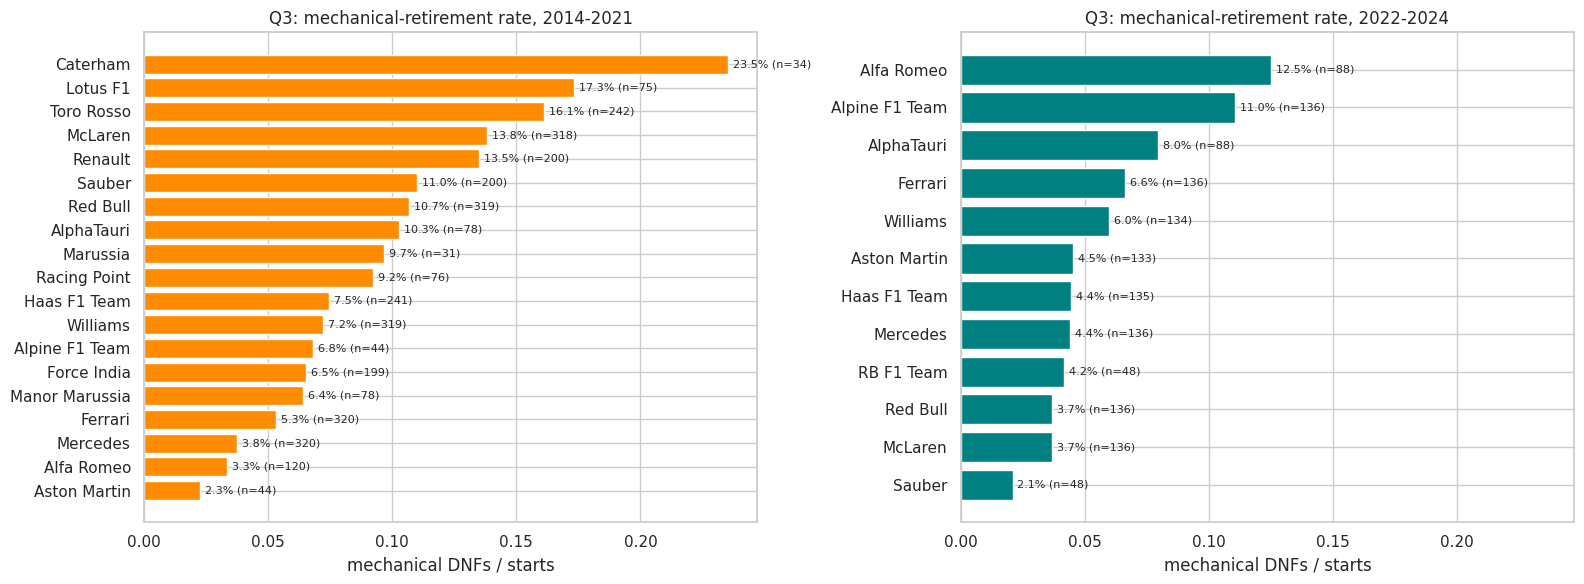

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
for ax, per, col in zip(axes, ['2014-2021', '2022-2024'], ['darkorange', 'teal']):
    d = q3[q3['period'] == per].sort_values('mech_rate')
    ax.barh(d['constructor_name'], d['mech_rate'], color=col)
    for yv, (r_, n) in enumerate(zip(d['mech_rate'], d['starts'])):
        ax.text(r_ + 0.002, yv, f'{r_:.1%} (n={n})', va='center', fontsize=8)
    ax.set_title(f'Q3: mechanical-retirement rate, {per}'); ax.set_xlabel('mechanical DNFs / starts')
plt.tight_layout(); plt.show()

**Answer Q3.**
- **2014–2021:** highest mechanical-retirement rates were **Caterham 23.5 %** (only 34 starts, so treat with caution), **Lotus F1 17.3 %**, **Toro Rosso 16.1 %**, **McLaren 13.8 %** (the McLaren-Honda years) and **Renault 13.5 %**. The most reliable were Aston Martin, Alfa Romeo and Mercedes (2–4 %).
- **2022–2024:** **Alfa Romeo 12.5 %**, **Alpine 11.0 %**, **AlphaTauri 8.0 %**, Ferrari 6.6 %, Williams 6.0 %; Red Bull and McLaren were the most reliable (3.7 %).
- **Overall**, mechanical failures fell from **9.2 %** of starts (2014–2021, the new turbo-hybrid power units) to **6.0 %** (2022–2024, mature power units with engine development frozen).
**Grain & missingness:** one row per start; *Retired* (cause unknown) and damage/puncture-type statuses are excluded as ambiguous, so the true mechanical rate may be slightly higher. Team rebrands (e.g. Toro Rosso → AlphaTauri → RB) appear as separate constructors.

## 4. Leakage-safe feature engineering

**Rule:** a feature is allowed only if its value is known **after qualifying and before the race starts**.

| Excluded (known only after the race — leakage) | Why |
|---|---|
| `position`, `positionOrder`, `points`, `laps`, `time`, `milliseconds`, `status`, `fastestLap*` | results of the race we are predicting |
| `lap_times`, `pit_stops` of the current race | happen during the race |
| `driver_standings` / `constructor_standings` **of the current raceId** | Ergast stores standings **after** each race |

Features are grouped so we can later remove one group at a time (ablation):

| Group | Features | Pre-race because… |
|---|---|---|
| **grid** | `grid_pos`, `front_row`, `pit_lane_start` | starting grid is fixed before the start |
| **qualifying** | `quali_pos`, `quali_gap_pct` (% slower than pole), `grid_minus_quali` (penalties) | qualifying has finished |
| **form** | driver podium rate, average finish and finish rate over the **previous 5 races**; team podium rate over its previous 5 races; driver's previous podium rate at this circuit | computed with `shift(1)` → only *earlier* races |
| **standings** | championship position, points share of the leader and wins **before** the race (standings of the *previous round*) | previous round's standings are published |
| **context** | `career_starts`, `driver_age`, `home_race`, `field_size` | known before the race |

Form features are computed on the **full history (1950–2024)** and only then filtered to 2003–2024, so early-2003 rows still have form from 2002 (tested in Experiment E3).

In [28]:
df = entries[entries['started']].copy()
df['finished'] = df['status'].str.match(r'^(Finished|\+\d+ Laps?)$').astype(int)

# ---- grid group
df['field_size'] = df.groupby('raceId')['driverId'].transform('size')
df['pit_lane_start'] = (df['grid'] == 0).astype(int)
df['grid_pos'] = df['grid'].where(df['grid'] > 0, df['field_size'])          # pit-lane start = back of the grid
df['front_row'] = (df['grid_pos'] <= 2).astype(int)

# ---- qualifying group
df['best_quali_sec'] = df[['q1_sec', 'q2_sec', 'q3_sec']].min(axis=1)
pole = df.groupby('raceId')['best_quali_sec'].transform('min')
df['quali_gap_pct'] = (100 * (df['best_quali_sec'] - pole) / pole).clip(upper=10)
df['grid_minus_quali'] = df['grid_pos'] - df['quali_pos']

# ---- form group (previous races only: shift(1) excludes the current race)
df = df.sort_values(['date', 'raceId'])
def past_rolling(g, col, n=5):
    return g[col].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())
gd = df.groupby('driverId')
df['drv_podium_rate_last5'] = past_rolling(gd, 'podium')
df['drv_avg_finish_last5'] = past_rolling(gd, 'positionOrder')
df['drv_finish_rate_last5'] = past_rolling(gd, 'finished')
df['career_starts'] = gd.cumcount()
df['drv_circuit_podium_rate'] = df.groupby(['driverId', 'circuitId'])['podium'].transform(lambda s: s.shift(1).expanding().mean())

team_race = df.groupby(['constructorId', 'raceId', 'date'], as_index=False)['podium'].mean().sort_values('date')
team_race['team_podium_rate_last5'] = team_race.groupby('constructorId')['podium'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df = df.merge(team_race[['constructorId', 'raceId', 'team_podium_rate_last5']], on=['constructorId', 'raceId'], how='left')

# ---- standings group: standings after the PREVIOUS round of the same season
rs = clean['races'].sort_values(['year', 'round'])[['raceId', 'year']].copy()
rs['prev_raceId'] = rs.groupby('year')['raceId'].shift(1)
df = df.merge(rs[['raceId', 'prev_raceId']], on='raceId', how='left')
ds = clean['driver_standings'][['raceId', 'driverId', 'points', 'position', 'wins']].rename(
    columns={'raceId': 'prev_raceId', 'points': 'drv_points_before', 'position': 'drv_champ_pos_before', 'wins': 'drv_wins_before'})
cs = clean['constructor_standings'][['raceId', 'constructorId', 'points', 'position']].rename(
    columns={'raceId': 'prev_raceId', 'points': 'team_points_before', 'position': 'team_champ_pos_before'})
ds['prev_raceId'] = ds['prev_raceId'].astype(float); cs['prev_raceId'] = cs['prev_raceId'].astype(float)
df = df.merge(ds, on=['prev_raceId', 'driverId'], how='left').merge(cs, on=['prev_raceId', 'constructorId'], how='left')
for c in ['drv_points_before', 'drv_wins_before', 'team_points_before']:
    df[c] = df[c].fillna(0)                                   # not in the standings yet = 0 points / wins
lead_d = ds.groupby('prev_raceId')['drv_points_before'].max()
lead_t = cs.groupby('prev_raceId')['team_points_before'].max()
df['drv_points_share_before'] = (df['drv_points_before'] / df['prev_raceId'].map(lead_d)).fillna(0)
df['team_points_share_before'] = (df['team_points_before'] / df['prev_raceId'].map(lead_t)).fillna(0)

# ---- context group
df['driver_age'] = (df['date'] - df['dob']).dt.days / 365.25

FEATURE_GROUPS = {
    'grid': ['grid_pos', 'front_row', 'pit_lane_start'],
    'qualifying': ['quali_pos', 'quali_gap_pct', 'grid_minus_quali'],
    'form': ['drv_podium_rate_last5', 'drv_avg_finish_last5', 'drv_finish_rate_last5', 'team_podium_rate_last5', 'drv_circuit_podium_rate'],
    'standings': ['drv_champ_pos_before', 'drv_points_share_before', 'drv_wins_before', 'team_champ_pos_before', 'team_points_share_before'],
    'context': ['career_starts', 'driver_age', 'home_race', 'field_size'],
}
FEATURES = [f for g in FEATURE_GROUPS.values() for f in g]
TARGET = 'podium'
ID_COLS = ['raceId', 'driverId', 'year', 'round', 'date', 'race_name', 'forename', 'surname', 'constructor_name']

model_df = df[df['year'].between(2003, 2024)][ID_COLS + FEATURES + [TARGET]].sort_values(['date', 'raceId', 'grid_pos']).reset_index(drop=True)
assert not model_df.duplicated(['raceId', 'driverId']).any()
print('Modeling table:', model_df.shape, '| podium rate:', round(model_df[TARGET].mean(), 3))
model_df.head()

Modeling table: (8935, 30) | podium rate: 0.144


,raceId,driverId,year,round,date,race_name,forename,surname,constructor_name,grid_pos,front_row,pit_lane_start,quali_pos,quali_gap_pct,grid_minus_quali,drv_podium_rate_last5,drv_avg_finish_last5,drv_finish_rate_last5,team_podium_rate_last5,drv_circuit_podium_rate,drv_champ_pos_before,drv_points_share_before,drv_wins_before,team_champ_pos_before,team_points_share_before,career_starts,driver_age,home_race,field_size,podium
0,108,30,2003,1,2003-03-09,Australian Grand Prix,Michael,Schumacher,Ferrari,1,1,0,1.0,0.000000,0.0,1.0,1.6,1.0,1.0,0.571429,NaN,0.0,0.0,NaN,0.0,179,34.176591,0,20,0
1,108,22,2003,1,2003-03-09,Australian Grand Prix,Rubens,Barrichello,Ferrari,2,1,0,2.0,0.281050,0.0,1.0,1.4,1.0,1.0,0.285714,NaN,0.0,0.0,NaN,0.0,165,30.792608,0,20,0
2,108,31,2003,1,2003-03-09,Australian Grand Prix,Juan,Pablo Montoya,Williams,3,0,0,3.0,1.064550,0.0,0.2,7.2,0.8,0.2,0.500000,NaN,0.0,0.0,NaN,0.0,34,27.466119,0,20,1
3,108,49,2003,1,2003-03-09,Australian Grand Prix,Heinz-Harald,Frentzen,Sauber,4,0,0,4.0,1.263006,0.0,0.0,15.4,0.6,0.0,0.285714,NaN,0.0,0.0,NaN,0.0,140,35.808350,0,20,0
4,108,44,2003,1,2003-03-09,Australian Grand Prix,Olivier,Panis,Toyota,5,0,0,5.0,1.279066,0.0,0.0,11.8,0.6,0.0,0.000000,NaN,0.0,0.0,NaN,0.0,125,36.514716,0,20,0


In [29]:
# Leakage check: recompute the driver form feature for random rows using ONLY strictly earlier races and compare
rng = np.random.default_rng(SEED)
hist = df[['driverId', 'date', 'podium']]
sample = model_df.sample(300, random_state=SEED)
recomputed = [hist[(hist.driverId == r.driverId) & (hist.date < r.date)].sort_values('date').tail(5)['podium'].mean()
              for r in sample.itertuples()]
same = np.allclose(np.nan_to_num(recomputed, nan=-1), sample['drv_podium_rate_last5'].fillna(-1))
print('Form feature uses only past races (300 random rows re-checked):', same)

# Leakage check 2: pre-race standings must not include the current race's points
first_rounds = model_df[model_df['round'] == 1]
print('Round-1 rows with non-zero points before the race:', int((first_rounds['drv_points_share_before'] > 0).sum()))

Form feature uses only past races (300 random rows re-checked): True
Round-1 rows with non-zero points before the race: 0


### 4.1 Evidence for the chosen features

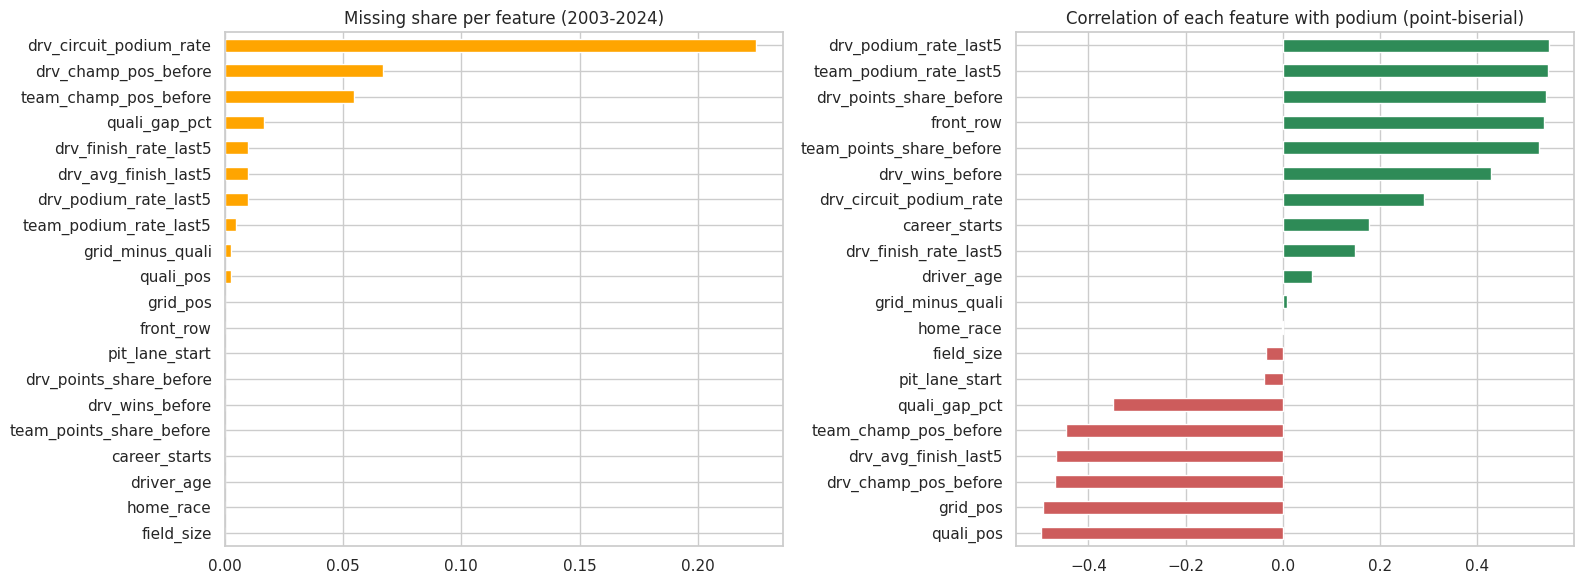

In [30]:
# Missingness of every feature in the modeling table
miss = model_df[FEATURES].isna().mean().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
miss.plot.barh(ax=axes[0], color='orange'); axes[0].set_title('Missing share per feature (2003-2024)'); axes[0].invert_yaxis()

corr = model_df[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
corr.plot.barh(ax=axes[1], color=np.where(corr > 0, 'seagreen', 'indianred'))
axes[1].set_title('Correlation of each feature with podium (point-biserial)')
plt.tight_layout(); plt.show()

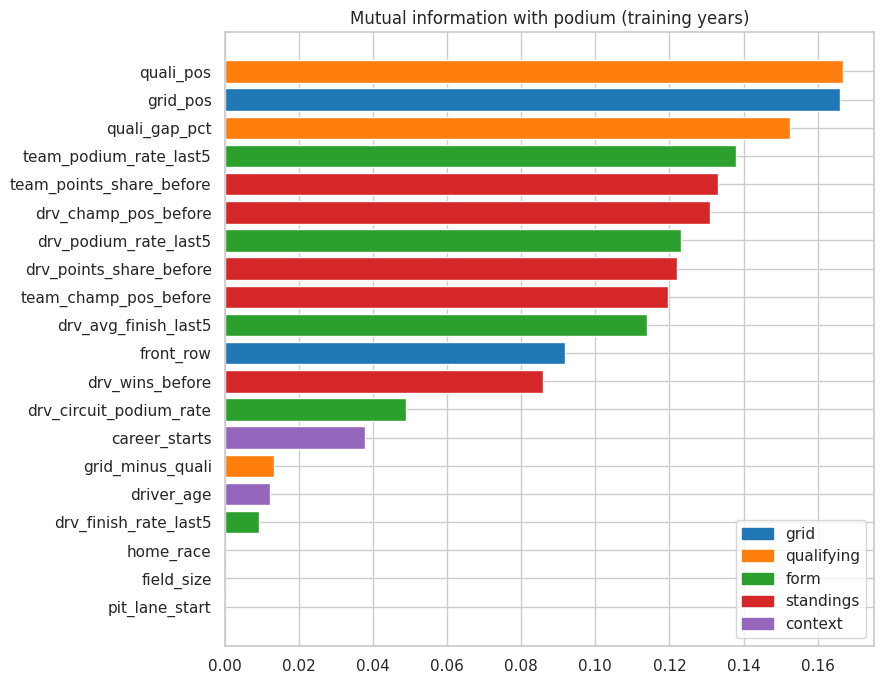

In [31]:
# Mutual information (captures non-linear relationships too), computed on the training years only
train_mask = model_df['year'] <= 2018
mi_X = model_df.loc[train_mask, FEATURES].fillna(model_df.loc[train_mask, FEATURES].median())
mi = pd.Series(mutual_info_classif(mi_X, model_df.loc[train_mask, TARGET], random_state=SEED), index=FEATURES).sort_values()
group_of = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
palette = dict(zip(FEATURE_GROUPS, sns.color_palette('tab10', len(FEATURE_GROUPS))))
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(mi.index, mi.values, color=[palette[group_of[f]] for f in mi.index])
ax.set_title('Mutual information with podium (training years)')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()], labels=list(palette), loc='lower right')
plt.tight_layout(); plt.show()

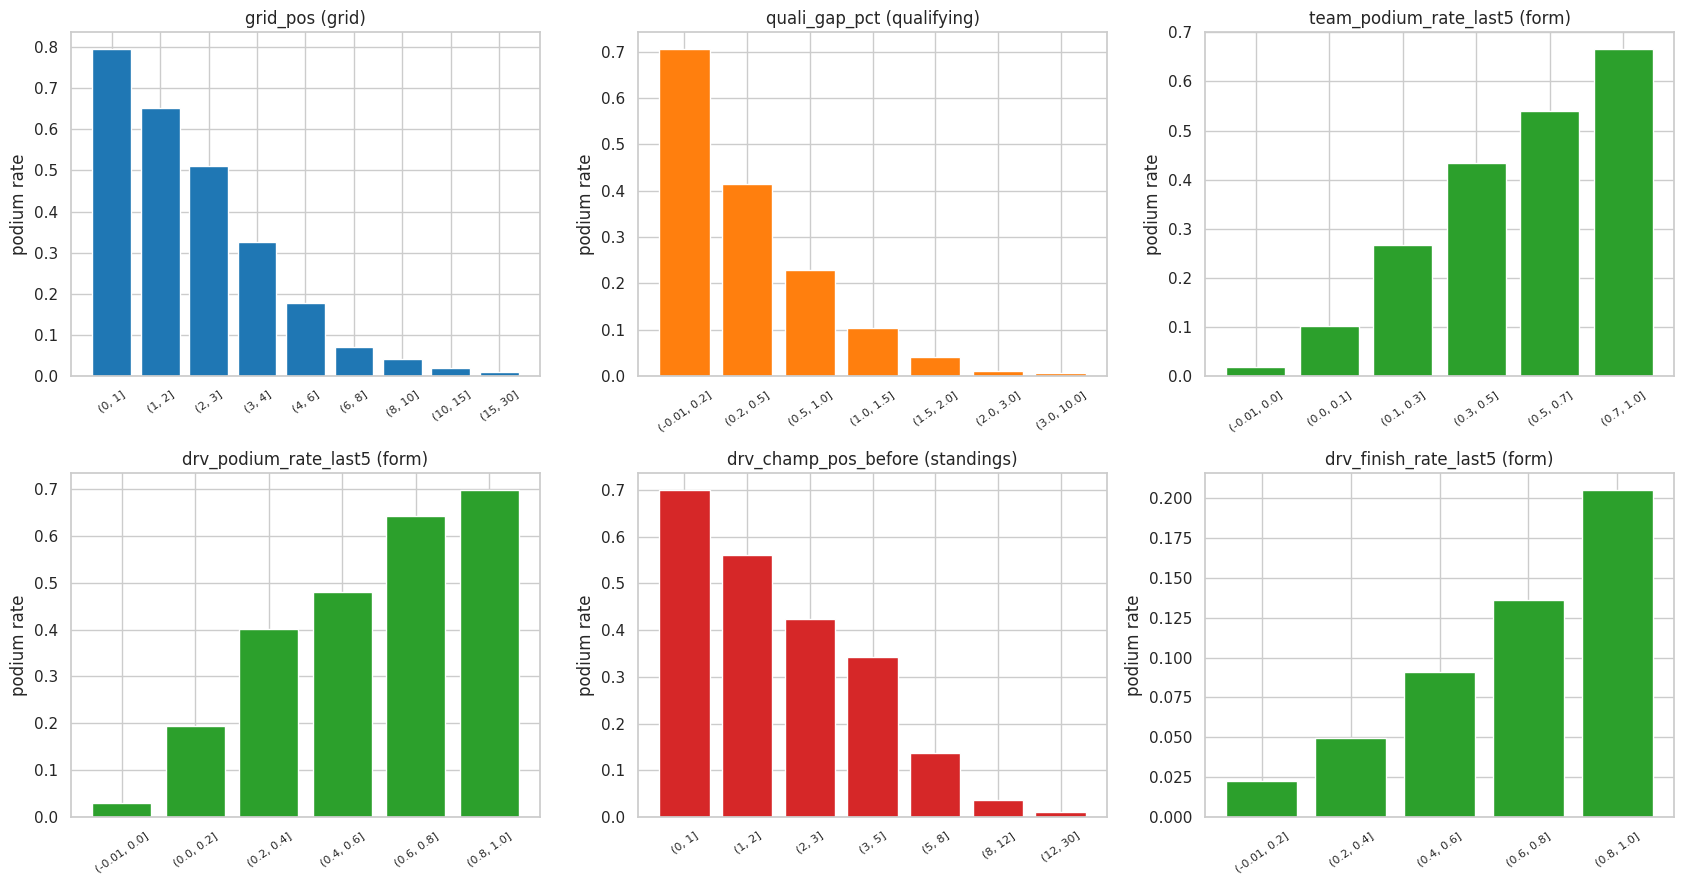

In [32]:
# Effect plots: podium rate across the range of key features
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
plots = [('grid_pos', [0, 1, 2, 3, 4, 6, 8, 10, 15, 30]), ('quali_gap_pct', [-0.01, 0.2, 0.5, 1, 1.5, 2, 3, 10]),
         ('team_podium_rate_last5', [-0.01, 0, 0.1, 0.3, 0.5, 0.7, 1]), ('drv_podium_rate_last5', [-0.01, 0, 0.2, 0.4, 0.6, 0.8, 1]),
         ('drv_champ_pos_before', [0, 1, 2, 3, 5, 8, 12, 30]), ('drv_finish_rate_last5', [-0.01, 0.2, 0.4, 0.6, 0.8, 1])]
for ax, (f, bins) in zip(axes.ravel(), plots):
    b = pd.cut(model_df[f], bins)
    t = model_df.groupby(b, observed=True)[TARGET].agg(['mean', 'size'])
    ax.bar(range(len(t)), t['mean'], color=palette[group_of[f]])
    ax.set_xticks(range(len(t))); ax.set_xticklabels([str(i) for i in t.index], rotation=35, fontsize=8)
    ax.set_title(f'{f} ({group_of[f]})'); ax.set_ylabel('podium rate')
plt.tight_layout(); plt.show()

**Feature justification (hypothesis-driven, from the EDA above):**
- **Grid / qualifying** have by far the strongest relationship with podiums (steep monotone drop in podium rate; highest correlation and mutual information). `quali_gap_pct` adds *how far* off pole a driver was — two drivers can be 4th and 5th but 0.1 % or 1 % off the pace.
- **Form** (team podium rate in the last 5 races especially) captures car competitiveness that the grid alone misses, e.g. a fast car starting out of position after a penalty.
- **Standings** summarize the whole season so far; using the leader's **points share** instead of raw points makes 2003 (10 points for a win) and 2010+ (25 points) comparable.
- **Context** features are weak individually (`home_race`, `pit_lane_start` and `field_size` have ≈ 0 mutual information; `field_size` is almost always 20 after 2003). They are kept as a hypothesis to test: ablation in Section 7 measures whether they help at all.
- Missing values are structural: form/standings are missing at a driver's debut or round 1, `quali_gap_pct` when no time was set. The models handle them with imputation + missing-indicators or natively.

## 5. Train / validation / test split and preprocessing

**Temporal split by season** (no race is split across sets):

| set | seasons | purpose |
|---|---|---|
| train | 2003–2018 | fit the models |
| validation | 2019–2021 | choose hyperparameters, thresholds, model |
| test | 2022–2024 | final, untouched evaluation |

**Why temporal and not random:** the real use is predicting *future* races from the past. A random split would put races from 2023 in training and 2010 in testing, letting the model learn the future (e.g. which team dominates) and overstating performance. The test seasons also start a new technical era (2022 ground-effect rules), which makes the test an honest check of generalization.

,seasons,races,rows,podium_rate
split,,,,
train,2003-2018,300,6383,0.141
val,2019-2021,60,1198,0.150
test,2022-2024,68,1354,0.151


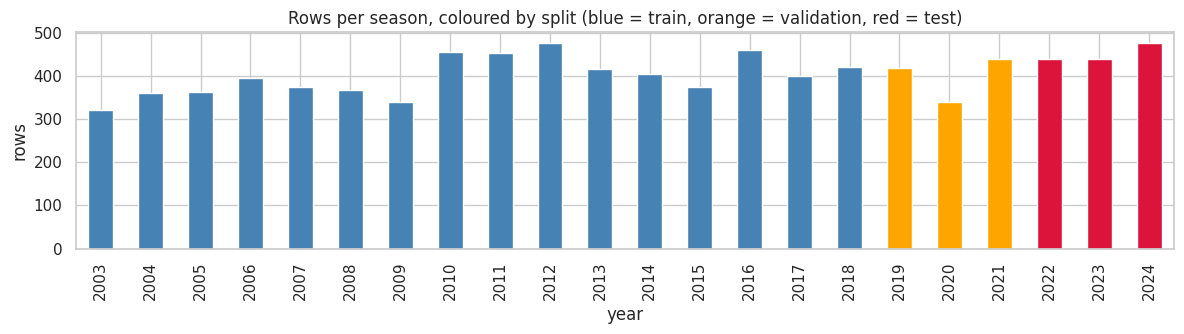

In [33]:
split = np.select([model_df['year'] <= 2018, model_df['year'] <= 2021], ['train', 'val'], 'test')
model_df['split'] = split
X_train, y_train = model_df.loc[split == 'train', FEATURES], model_df.loc[split == 'train', TARGET]
X_val, y_val = model_df.loc[split == 'val', FEATURES], model_df.loc[split == 'val', TARGET]
X_test, y_test = model_df.loc[split == 'test', FEATURES], model_df.loc[split == 'test', TARGET]

summary = model_df.groupby('split').agg(seasons=('year', lambda s: f'{s.min()}-{s.max()}'), races=('raceId', 'nunique'),
                                        rows=(TARGET, 'size'), podium_rate=(TARGET, 'mean')).loc[['train', 'val', 'test']]
display(summary.round(3))
fig, ax = plt.subplots(figsize=(12, 3.5))
model_df.groupby('year')[TARGET].size().plot.bar(ax=ax, color=[{'train': 'steelblue', 'val': 'orange', 'test': 'crimson'}[s] for s in model_df.groupby('year')['split'].first()])
ax.set_title('Rows per season, coloured by split (blue = train, orange = validation, red = test)'); ax.set_ylabel('rows')
plt.tight_layout(); plt.show()

**Preprocessing per model family** (always fitted on the training set only, inside a `Pipeline`):
- **Logistic regression & neural network:** median imputation **+ missing-indicator columns** (so the model knows a value was missing) → standardization (mean 0, std 1). Both are sensitive to feature scale.
- **Random forest:** median imputation only (trees split on thresholds, scale does not matter).
- **Histogram gradient boosting:** no preprocessing — it handles missing values natively.

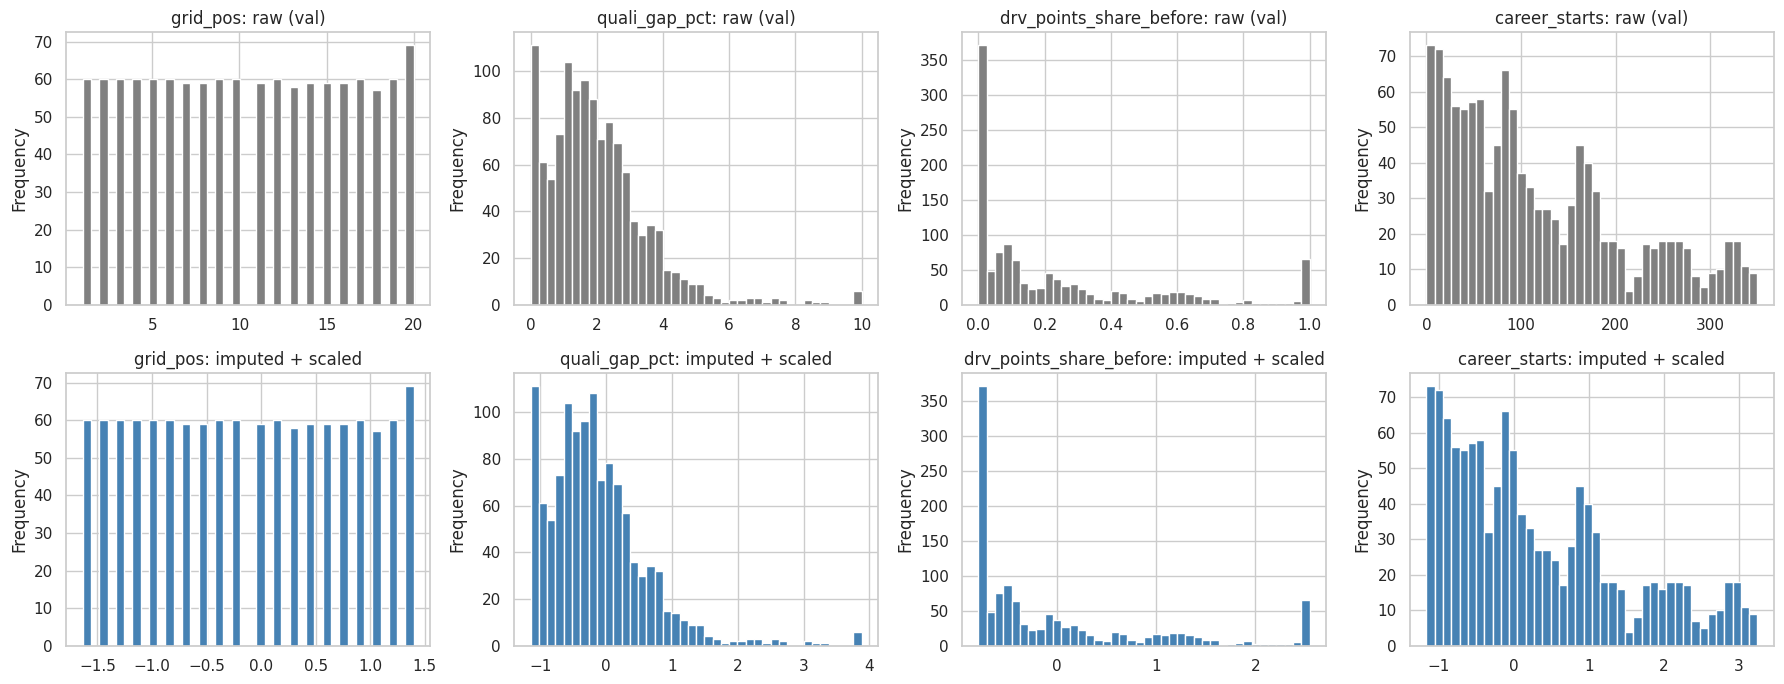

,raw mean,raw std,raw missing %,processed mean,processed std,processed missing %
grid_pos,10.54,5.81,0.00,-0.11,0.93,0.0
front_row,0.10,0.30,0.00,0.02,1.03,0.0
pit_lane_start,0.02,0.15,0.00,0.57,3.89,0.0
quali_pos,10.47,5.76,0.25,-0.12,0.92,0.0
quali_gap_pct,1.99,1.52,1.67,-0.15,0.76,0.0
grid_minus_quali,0.04,1.83,0.25,0.03,1.18,0.0
drv_podium_rate_last5,0.15,0.27,0.75,0.04,1.06,0.0
drv_avg_finish_last5,10.46,4.21,0.75,-0.15,0.93,0.0
drv_finish_rate_last5,0.85,0.16,0.75,0.40,0.76,0.0
team_podium_rate_last5,0.15,0.24,0.50,0.02,1.05,0.0


In [34]:
def make_linear_prep():
    return Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())])

prep_demo = make_linear_prep().fit(X_train)
Xt_demo = pd.DataFrame(prep_demo.transform(X_val)[:, :len(FEATURES)], columns=FEATURES)

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, f in enumerate(['grid_pos', 'quali_gap_pct', 'drv_points_share_before', 'career_starts']):
    X_val[f].plot.hist(bins=40, ax=axes[0, i], color='gray'); axes[0, i].set_title(f'{f}: raw (val)')
    Xt_demo[f].plot.hist(bins=40, ax=axes[1, i], color='steelblue'); axes[1, i].set_title(f'{f}: imputed + scaled')
plt.tight_layout(); plt.show()
eff = pd.DataFrame({'raw mean': X_val[FEATURES].mean(), 'raw std': X_val[FEATURES].std(), 'raw missing %': 100 * X_val[FEATURES].isna().mean(),
                    'processed mean': Xt_demo.mean().values, 'processed std': Xt_demo.std().values, 'processed missing %': 0.0})
eff.round(2)

The preprocessing changes the **range**, not the **shape**: every feature is centred near 0 with spread ≈ 1 (validation values are transformed with the *training* mean/std, so they are close to, not exactly, 0/1), and missing values are filled — the imputed values show up as a spike at the median. The extra indicator columns keep the information *that* a value was missing.

## 6. Predictive models

**Metrics** (all computed for every model on train, validation and test):

| metric | what it measures |
|---|---|
| ROC-AUC | how well the model separates podium from non-podium overall (threshold-free) |
| **PR-AUC** (primary) | how well true podium finishers are ranked above others; more informative than ROC-AUC because podiums are rare (~14 %) |
| F1 (secondary) | balance of precision and recall at the chosen threshold |
| Precision | of the drivers we predict on the podium, how many were |
| Recall | of the actual podium finishers, how many we caught |

**Primary metric = PR-AUC:** the positive class is rare and the useful output is a ranking of who is likely to podium; ROC-AUC looks optimistic when negatives dominate. **Secondary = F1** at a threshold chosen to maximise F1 on the **validation** set (never the test set).

**Models:**
- **Baseline 0 — "grid rule":** predict a podium for the top-3 starters. The simplest reasonable approach; any model must beat it.
- **Model 1 — Logistic regression** (statistical baseline model required by the brief).
- **Model 2 — Random forest** (3 hyperparameter variants).
- **Model 3 — Histogram gradient boosting** (3 variants).
- **Model 4 — Shallow neural network** (2 architectures, 1–2 hidden layers).

In [35]:
def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.nanargmax(f1[:-1])])

def scores(y, p, thr):
    pred = (p >= thr).astype(int)
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p), 'F1': f1_score(y, pred),
            'Precision': precision_score(y, pred, zero_division=0), 'Recall': recall_score(y, pred)}

RESULTS, PROBS = [], {}
def evaluate(name, p_train, p_val, p_test, thr=None, family=''):
    thr = best_threshold(y_val, p_val) if thr is None else thr
    for s, y, p in [('train', y_train, p_train), ('val', y_val, p_val), ('test', y_test, p_test)]:
        RESULTS.append({'model': name, 'family': family, 'split': s, 'threshold': thr, **scores(y, p, thr)})
    PROBS[name] = {'val': p_val, 'test': p_test, 'thr': thr}
    return pd.DataFrame([r for r in RESULTS if r['model'] == name]).set_index('split')[['ROC-AUC', 'PR-AUC', 'F1', 'Precision', 'Recall']].round(3)

def fit_eval(name, model, family):
    model.fit(X_train, y_train)
    p = [model.predict_proba(X)[:, 1] for X in (X_train, X_val, X_test)]
    return model, evaluate(name, *p, family=family)

# Baseline 0: grid rule (score = negative grid position, threshold = top 3 on the grid)
evaluate('Baseline: grid <= 3', -X_train['grid_pos'].values, -X_val['grid_pos'].values, -X_test['grid_pos'].values, thr=-3, family='baseline')

,ROC-AUC,PR-AUC,F1,Precision,Recall
split,,,,,
train,0.907,0.620,0.639,0.641,0.638
val,0.917,0.677,0.717,0.717,0.717
test,0.914,0.647,0.649,0.650,0.647


### 6.1 Logistic regression (statistical baseline)
**How it works:** computes a weighted sum of the (scaled) features and passes it through a sigmoid to get a probability; the weights are learned by maximising the likelihood of the training labels.
**Limitations:** it can only draw a straight (linear) boundary in feature space — e.g. it cannot learn that "grid 1 *and* a dominant team" matters more than the sum of the two — and it needs scaled, imputed inputs.

In [36]:
logreg, t = fit_eval('Logistic regression', Pipeline([('prep', make_linear_prep()), ('clf', LogisticRegression(max_iter=2000))]), 'statistical')
t

,ROC-AUC,PR-AUC,F1,Precision,Recall
split,,,,,
train,0.932,0.697,0.671,0.572,0.810
val,0.938,0.735,0.729,0.645,0.839
test,0.937,0.718,0.672,0.550,0.863


### 6.2 Random forest (3 variants)
**How it works:** trains many decision trees, each on a bootstrap sample of the rows and a random subset of features, and averages their votes. Averaging reduces the overfitting of a single tree.
**Limitations:** less interpretable than one tree, probabilities are not well calibrated, and deep trees can still memorise the training set (watch the train vs validation gap).

In [37]:
rf_variants = {'RF depth 6': dict(max_depth=6), 'RF depth 10': dict(max_depth=10), 'RF unlimited': dict(max_depth=None)}
rf_models = {}
for name, kw in rf_variants.items():
    rf_models[name], t = fit_eval(name, Pipeline([('impute', SimpleImputer(strategy='median')),
                                                  ('clf', RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=N_JOBS, random_state=SEED, **kw))]), 'statistical')
    print(name); display(t)

RF depth 6


,ROC-AUC,PR-AUC,F1,Precision,Recall
split,,,,,
train,0.952,0.781,0.717,0.653,0.796
val,0.940,0.744,0.733,0.676,0.800
test,0.939,0.709,0.683,0.627,0.750


RF depth 10


,ROC-AUC,PR-AUC,F1,Precision,Recall
split,,,,,
train,0.977,0.885,0.780,0.698,0.883
val,0.938,0.736,0.727,0.667,0.800
test,0.937,0.686,0.670,0.608,0.745


RF unlimited


,ROC-AUC,PR-AUC,F1,Precision,Recall
split,,,,,
train,0.983,0.911,0.806,0.737,0.889
val,0.939,0.737,0.726,0.673,0.789
test,0.936,0.684,0.671,0.621,0.730


### 6.3 Histogram gradient boosting (3 variants)
**How it works:** builds trees one after another, each new tree correcting the errors of the ones before (gradient boosting). Features are bucketed into histograms, which makes it fast, and missing values are routed to the best side of each split automatically.
**Limitations:** many hyperparameters, can overfit with too many/too deep trees, and is a black box that needs XAI to interpret.

In [38]:
hgb_variants = {'HGB lr 0.05, depth 3': dict(learning_rate=0.05, max_depth=3, max_iter=300),
                'HGB lr 0.05, depth 6': dict(learning_rate=0.05, max_depth=6, max_iter=300),
                'HGB lr 0.1, no depth limit': dict(learning_rate=0.1, max_depth=None, max_iter=300)}
hgb_models = {}
for name, kw in hgb_variants.items():
    hgb_models[name], t = fit_eval(name, HistGradientBoostingClassifier(random_state=SEED, **kw), 'statistical')
    print(name); display(t)

HGB lr 0.05, depth 3


,ROC-AUC,PR-AUC,F1,Precision,Recall
split,,,,,
train,0.962,0.816,0.749,0.672,0.846
val,0.937,0.728,0.715,0.654,0.789
test,0.931,0.674,0.646,0.589,0.716


HGB lr 0.05, depth 6


,ROC-AUC,PR-AUC,F1,Precision,Recall
split,,,,,
train,0.996,0.975,0.873,0.783,0.988
val,0.929,0.698,0.704,0.651,0.767
test,0.922,0.640,0.661,0.607,0.725


HGB lr 0.1, no depth limit


,ROC-AUC,PR-AUC,F1,Precision,Recall
split,,,,,
train,1.000,1.000,0.994,0.988,1.000
val,0.924,0.669,0.703,0.667,0.744
test,0.920,0.626,0.647,0.601,0.701


### 6.4 Shallow neural network (2 architectures)
**How it works:** a feed-forward network (as in Lab 3): scaled features → 1–2 fully connected hidden layers with ReLU → one sigmoid output = podium probability, trained with binary cross-entropy (log-loss) and the Adam optimizer in mini-batches of 64.
- **Library:** scikit-learn's `MLPClassifier` (a standard library, as the brief allows). We use it instead of Keras because TensorFlow alone needs ~550 MB of RAM, more than half of a 1 GB Kaggle session.
- **Early stopping on our metric:** each call to `partial_fit` trains one epoch; after every epoch we score the **validation PR-AUC** and keep a copy of the best epoch, stopping after 15 epochs without improvement (the same rule as Keras' `EarlyStopping(restore_best_weights=True)`).
- **Regularization:** L2 weight penalty (`alpha=1e-3`) instead of dropout — it keeps weights small so the network cannot memorise the training set.
**Limitations:** needs scaled and imputed inputs, and on small tabular data it rarely beats tree ensembles.

In [39]:
nn_prep = make_linear_prep().fit(X_train)
Xtr_nn, Xva_nn, Xte_nn = (nn_prep.transform(X) for X in (X_train, X_val, X_test))

def train_shallow_nn(hidden, max_epochs=200, patience=15):
    # one partial_fit call = one epoch of mini-batch Adam; keep the epoch with the best validation PR-AUC (early stopping)
    net = MLPClassifier(hidden_layer_sizes=hidden, activation='relu', solver='adam', learning_rate_init=1e-3,
                        batch_size=64, alpha=1e-3, random_state=SEED)
    hist = {'loss': [], 'val_loss': [], 'pr_auc': [], 'val_pr_auc': []}
    best, best_net, wait = -1.0, None, 0
    for epoch in range(max_epochs):
        net.partial_fit(Xtr_nn, y_train, classes=[0, 1])
        p_tr, p_va = net.predict_proba(Xtr_nn)[:, 1], net.predict_proba(Xva_nn)[:, 1]
        hist['loss'].append(log_loss(y_train, p_tr)); hist['val_loss'].append(log_loss(y_val, p_va))
        hist['pr_auc'].append(average_precision_score(y_train, p_tr)); hist['val_pr_auc'].append(average_precision_score(y_val, p_va))
        if hist['val_pr_auc'][-1] > best:
            best, best_net, wait = hist['val_pr_auc'][-1], copy.deepcopy(net), 0
        else:
            wait += 1
            if wait >= patience:
                break
    return best_net, hist

nn_histories, nn_models = {}, {}
for name, hidden in {'NN 1 layer (16)': (16,), 'NN 2 layers (32-16)': (32, 16)}.items():
    model, hist = train_shallow_nn(hidden)
    nn_histories[name], nn_models[name] = hist, model
    p = [model.predict_proba(X)[:, 1] for X in (Xtr_nn, Xva_nn, Xte_nn)]
    best_epoch = int(np.argmax(hist['val_pr_auc'])) + 1
    print(f'{name}: trained {len(hist["loss"])} epochs, best epoch {best_epoch}'); display(evaluate(name, *p, family='neural network'))

NN 1 layer (16): trained 44 epochs, best epoch 29


,ROC-AUC,PR-AUC,F1,Precision,Recall
split,,,,,
train,0.936,0.709,0.663,0.586,0.764
val,0.932,0.711,0.726,0.653,0.817
test,0.932,0.707,0.657,0.576,0.765


NN 2 layers (32-16): trained 23 epochs, best epoch 8


,ROC-AUC,PR-AUC,F1,Precision,Recall
split,,,,,
train,0.936,0.708,0.669,0.589,0.772
val,0.933,0.726,0.728,0.661,0.811
test,0.933,0.701,0.681,0.596,0.794


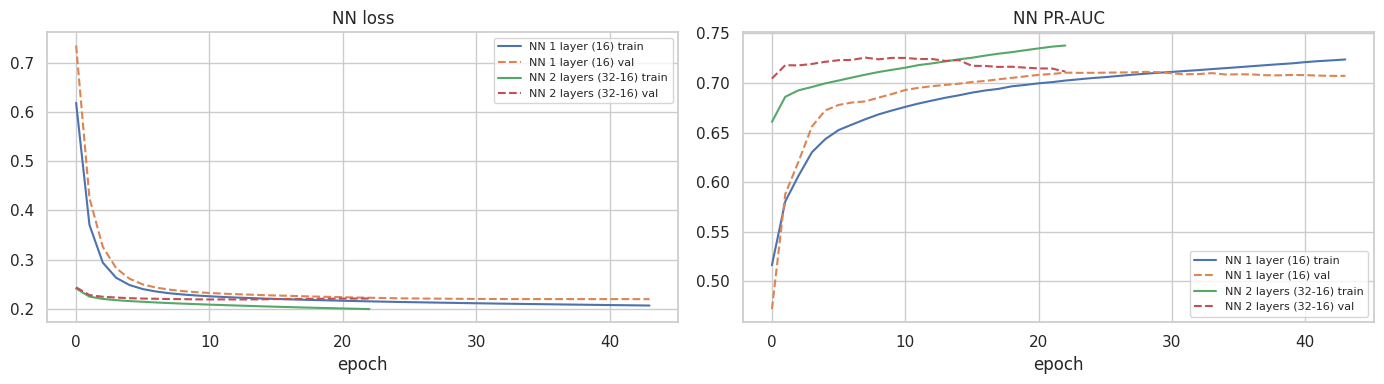

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, h in nn_histories.items():
    axes[0].plot(h['loss'], label=f'{name} train'); axes[0].plot(h['val_loss'], '--', label=f'{name} val')
    axes[1].plot(h['pr_auc'], label=f'{name} train'); axes[1].plot(h['val_pr_auc'], '--', label=f'{name} val')
axes[0].set_title('NN loss'); axes[1].set_title('NN PR-AUC'); axes[0].set_xlabel('epoch'); axes[1].set_xlabel('epoch')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

### 6.5 Model comparison

In [41]:
res_df = pd.DataFrame(RESULTS)
comparison = res_df.pivot_table(index=['family', 'model'], columns='split', values=['PR-AUC', 'ROC-AUC', 'F1', 'Precision', 'Recall'], sort=False)
comparison = comparison.reindex(columns=pd.MultiIndex.from_product([['PR-AUC', 'ROC-AUC', 'F1', 'Precision', 'Recall'], ['train', 'val', 'test']]))
display(comparison.round(3))

val_rank = res_df[res_df.split == 'val'].set_index('model')['PR-AUC'].sort_values(ascending=False)
BEST = val_rank.drop('Baseline: grid <= 3').index[0]
print('Validation PR-AUC ranking:\n', val_rank.round(4).to_string())
print('\nSelected model (best validation PR-AUC):', BEST)

PR-AUC               ROC-AUC                   F1               Precision               Recall              
                                           train    val   test   train    val   test  train    val   test     train    val   test  train    val   test
family         model                                                                                                                                  
baseline       Baseline: grid <= 3         0.620  0.677  0.647   0.907  0.917  0.914  0.639  0.717  0.649     0.641  0.717  0.650  0.638  0.717  0.647
statistical    Logistic regression         0.697  0.735  0.718   0.932  0.938  0.937  0.671  0.729  0.672     0.572  0.645  0.550  0.810  0.839  0.863
               RF depth 6                  0.781  0.744  0.709   0.952  0.940  0.939  0.717  0.733  0.683     0.653  0.676  0.627  0.796  0.800  0.750
               RF depth 10                 0.885  0.736  0.686   0.977  0.938  0.937  0.780  0.727  0.670     0.698  0.667  0.608  0.883  0.800  0.745
               RF unlimited                0.911  0.737  0.684   0.983  0.939  0.936  0.806  0.726  0.671     0.737  0.673  0.621  0.889  0.789  0.730
               HGB lr 0.05, depth 3        0.816  0.728  0.674   0.962  0.937  0.931  0.749  0.715  0.646     0.672  0.654  0.589  0.846  0.789  0.716
               HGB lr 0.05, depth 6        0.975  0.698  0.640   0.996  0.929  0.922  0.873  0.704  0.661     0.783  0.651  0.607  0.988  0.767  0.725
               HGB lr 0.1, no depth limit  1.000  0.669  0.626   1.000  0.924  0.920  0.994  0.703  0.647     0.988  0.667  0.601  1.000  0.744  0.701
neural network NN 1 layer (16)             0.709  0.711  0.707   0.936  0.932  0.932  0.663  0.726  0.657     0.586  0.653  0.576  0.764  0.817  0.765
               NN 2 layers (32-16)         0.708  0.726  0.701   0.936  0.933  0.933  0.669  0.728  0.681     0.589  0.661  0.596  0.772  0.811  0.794

Validation PR-AUC ranking:
 model
RF depth 6                    0.7443
RF unlimited                  0.7375
RF depth 10                   0.7359
Logistic regression           0.7347
HGB lr 0.05, depth 3          0.7275
NN 2 layers (32-16)           0.7255
NN 1 layer (16)               0.7111
HGB lr 0.05, depth 6          0.6979
Baseline: grid <= 3           0.6765
HGB lr 0.1, no depth limit    0.6689

Selected model (best validation PR-AUC): RF depth 6


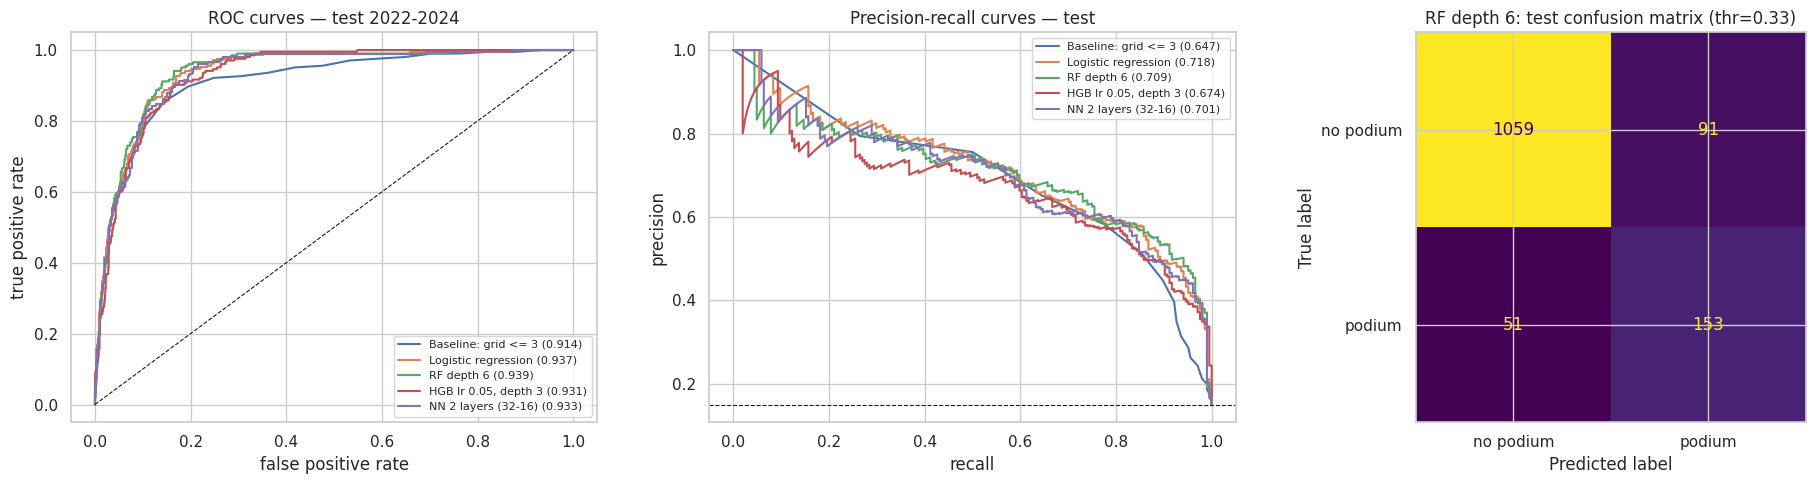

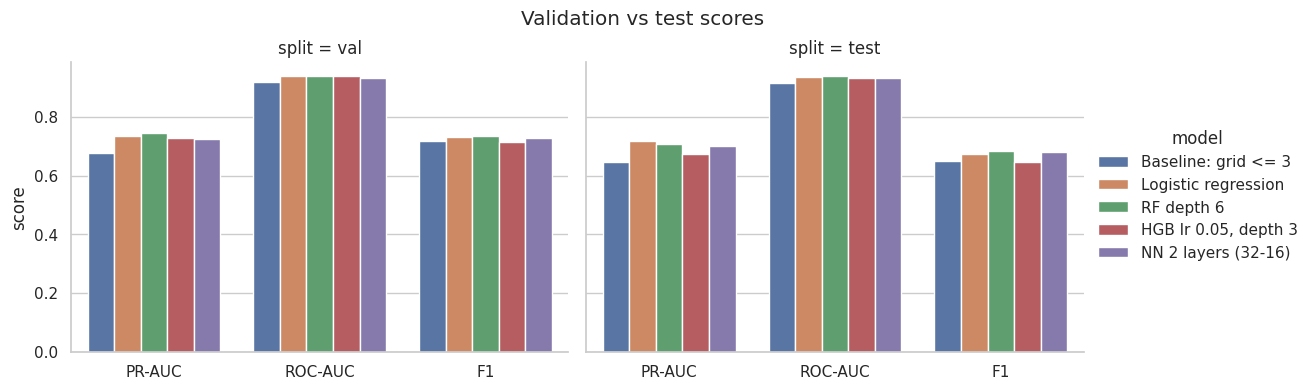

In [42]:
show = ['Baseline: grid <= 3', 'Logistic regression', max(rf_models, key=lambda m: val_rank[m]),
        max(hgb_models, key=lambda m: val_rank[m]), max(nn_models, key=lambda m: val_rank[m])]
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for m in show:
    p, thr = PROBS[m]['test'], PROBS[m]['thr']
    fpr, tpr, _ = roc_curve(y_test, p); prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f'{m} ({roc_auc_score(y_test, p):.3f})')
    axes[1].plot(rec, prec, label=f'{m} ({average_precision_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8); axes[0].set_title('ROC curves — test 2022-2024'); axes[0].set_xlabel('false positive rate'); axes[0].set_ylabel('true positive rate')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=0.8); axes[1].set_title('Precision-recall curves — test'); axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(y_test, (PROBS[BEST]['test'] >= PROBS[BEST]['thr']).astype(int)),
                       display_labels=['no podium', 'podium']).plot(ax=axes[2], colorbar=False)
axes[2].set_title(f'{BEST}: test confusion matrix (thr={PROBS[BEST]["thr"]:.2f})')
plt.tight_layout(); plt.show()

plot_df = res_df[res_df.model.isin(show) & res_df.split.isin(['val', 'test'])]
g = sns.catplot(data=plot_df.melt(id_vars=['model', 'split'], value_vars=['PR-AUC', 'ROC-AUC', 'F1']), x='variable', y='value',
                hue='model', col='split', kind='bar', height=4, aspect=1.4)
g.set_axis_labels('', 'score'); g.figure.suptitle('Validation vs test scores', y=1.03); plt.show()

In [43]:
# Keep only the models used later (selected model + best gradient boosting) to save memory on small sessions
keep = {BEST, max(hgb_models, key=lambda m: val_rank[m])}
for d in (rf_models, hgb_models):
    for m in [m for m in d if m not in keep]:
        del d[m]
gc.collect()
print('Kept for later sections:', sorted(keep))

Kept for later sections: ['HGB lr 0.05, depth 3', 'RF depth 6']


**Reading the comparison**
- **Baseline:** the grid rule already reaches PR-AUC 0.68 (val) / 0.65 (test) — starting position explains most of the problem.
- **Every learned model beats it.** Selected model: **Random forest, depth 6** — best validation PR-AUC **0.745**; on the unseen 2022–2024 test set: **PR-AUC 0.709, ROC-AUC 0.939, F1 0.683** (precision 0.63, recall 0.75) at the validation-chosen threshold 0.33.
- Logistic regression is close behind (val 0.735) and even slightly better on test (0.718): the problem is mostly monotone ("further forward + faster car → podium"), which a linear model captures well.
- **Overfitting is visible in the train vs validation gap:** unlimited-depth gradient boosting reaches train PR-AUC 1.000 but only 0.672 on validation; deeper forests show the same pattern. Limiting depth (RF depth 6, HGB depth 3) generalizes best.
- The **shallow neural networks** (val PR-AUC 0.711–0.726, test 0.701–0.707) beat the baseline and roughly match logistic regression, but do not beat the tree ensembles — expected on ~6,400 rows of tabular data.
- The model is **chosen on validation PR-AUC only**; test scores are reported once, afterwards.

## 7. Experiments

### 7.1 Feature-group ablation
Remove one feature group at a time, retrain the selected model type on the remaining features, and measure how much validation/test performance drops. Feature evidence in Section 4 justified each feature *before* training; ablation measures each group's *actual* contribution *after* training.

Ablation model: RF depth 6


,n features,val PR-AUC,test PR-AUC,val ROC-AUC,test ROC-AUC,Δ val PR-AUC,Δ test PR-AUC
removed group,,,,,,,
none (all features),20,0.7443,0.7089,0.9398,0.9391,0.0000,0.0000
grid,17,0.7302,0.6915,0.9373,0.9357,-0.0141,-0.0175
qualifying,17,0.7257,0.7189,0.9383,0.9386,-0.0186,0.0099
form,15,0.7396,0.7103,0.9388,0.9392,-0.0047,0.0014
standings,15,0.7350,0.6944,0.9390,0.9380,-0.0093,-0.0145
context,16,0.7405,0.7102,0.9398,0.9388,-0.0038,0.0013
grid + qualifying,14,0.6476,0.5795,0.9099,0.8998,-0.0967,-0.1294
only grid,3,0.6774,0.6473,0.9197,0.9132,-0.0669,-0.0616


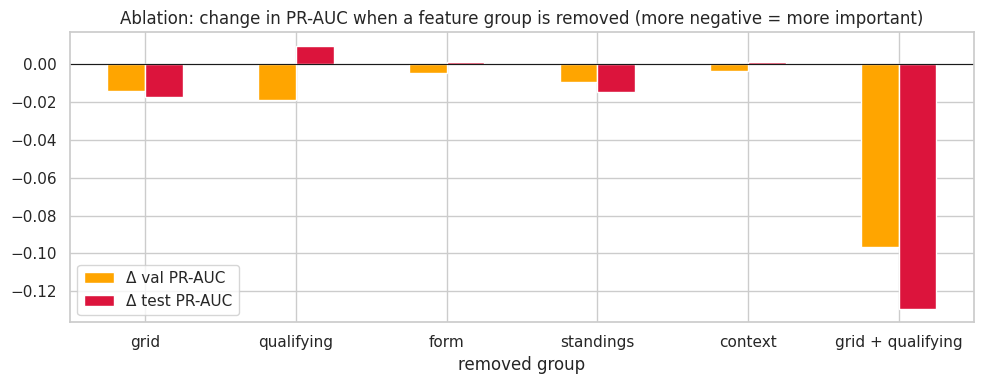

In [44]:
def make_model_like(name):
    if name in hgb_models:
        return HistGradientBoostingClassifier(random_state=SEED, **hgb_variants[name])
    if name in rf_models:
        return Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('clf', RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=N_JOBS, random_state=SEED, **rf_variants[name]))])
    return Pipeline([('prep', make_linear_prep()), ('clf', LogisticRegression(max_iter=2000))])

ABL_MODEL = BEST if (BEST in hgb_models or BEST in rf_models) else max(hgb_models, key=lambda m: val_rank[m])
print('Ablation model:', ABL_MODEL)
rows = []
for removed in ['none (all features)'] + list(FEATURE_GROUPS) + ['grid + qualifying', 'only grid']:
    if removed.startswith('none'):
        feats = FEATURES
    elif removed == 'only grid':
        feats = FEATURE_GROUPS['grid']
    elif removed == 'grid + qualifying':
        feats = [f for f in FEATURES if f not in FEATURE_GROUPS['grid'] + FEATURE_GROUPS['qualifying']]
    else:
        feats = [f for f in FEATURES if f not in FEATURE_GROUPS[removed]]
    m = make_model_like(ABL_MODEL).fit(X_train[feats], y_train)
    pv, pt = m.predict_proba(X_val[feats])[:, 1], m.predict_proba(X_test[feats])[:, 1]
    rows.append({'removed group': removed, 'n features': len(feats), 'val PR-AUC': average_precision_score(y_val, pv),
                 'test PR-AUC': average_precision_score(y_test, pt), 'val ROC-AUC': roc_auc_score(y_val, pv), 'test ROC-AUC': roc_auc_score(y_test, pt)})
ablation = pd.DataFrame(rows).set_index('removed group')
full = ablation.loc['none (all features)']
ablation['Δ val PR-AUC'] = ablation['val PR-AUC'] - full['val PR-AUC']
ablation['Δ test PR-AUC'] = ablation['test PR-AUC'] - full['test PR-AUC']
display(ablation.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
d = ablation.drop(['none (all features)', 'only grid'])[['Δ val PR-AUC', 'Δ test PR-AUC']]
d.plot.bar(ax=ax, color=['orange', 'crimson']); ax.axhline(0, color='k', lw=0.8)
ax.set_title('Ablation: change in PR-AUC when a feature group is removed (more negative = more important)'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Reading the ablation (random forest, depth 6; reference val/test PR-AUC = 0.745 / 0.709):**
- Removing **any single group** changes PR-AUC by at most ~0.02. The groups **overlap**: grid and qualifying carry almost the same information (`grid_pos` ≈ `quali_pos` unless there is a penalty), and standings/form both describe car strength. When one group is removed, another covers for it.
- Removing **grid + qualifying together** is by far the largest drop (val **−0.097**, test **−0.129**): starting position is the core signal, provided by either group.
- **Standings** give the most consistent single-group contribution (−0.010 val, −0.015 test); **grid** comes next (−0.015 / −0.017).
- **Context** and **form** removals change scores by < 0.006 — inside run-to-run noise. Changes of ±0.01 on the test set (e.g. removing qualifying gives +0.010 on test but −0.019 on validation) are within noise for 1,354 test rows.
- **Only grid** reaches 0.677 val PR-AUC — the same as the grid-rule baseline — so all the other groups together add about **+0.07 PR-AUC**.

### 7.2 Preprocessing-order experiments
Three controlled experiments, each changing **only** the order/scope of one preprocessing step (logistic regression, because it is the model most sensitive to preprocessing).

- **E1 — fit preprocessing before vs after the split.** Fitting the imputer/scaler on *all* seasons lets statistics from the validation/test years leak into training.
- **E2 — impute then scale vs scale then impute.** Changes where the imputed value lands and the spread of the scaled feature.
- **E3 — compute form features before vs after filtering to 2003+.** Filtering first throws away 2002 history, so early-2003 rows lose their form features.

,val PR-AUC,test PR-AUC,val ROC-AUC,test ROC-AUC
E1a: prep fit on TRAIN only (correct),0.7347,0.7181,0.9382,0.9366
E1b: prep fit on ALL seasons (leaky),0.7345,0.7175,0.9381,0.9364
E2a: impute -> scale,0.7347,0.7181,0.9382,0.9366
E2b: scale -> impute,0.7318,0.7175,0.9366,0.9363
"E3a: form computed on full history, then filtered (ours)",0.7347,0.7181,0.9382,0.9366
"E3b: filtered to 2003+ first, then form computed",0.7343,0.7180,0.9379,0.9363


Missing form values in the 2003 season — ours: 82 | filtered-first: 412
career_starts mean in 2003 — ours: 79.9 | filtered-first: 7.1


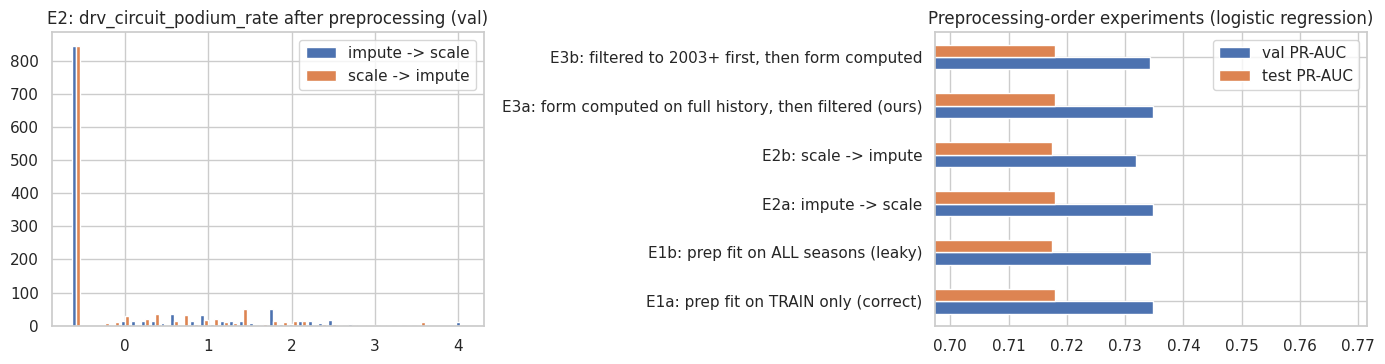

drv_circuit_podium_rate: impute->scale mean/std = 0.02/1.01 | scale->impute mean/std = -0.14/0.92


In [45]:
def lr_scores(Xtr, Xva, Xte, prep_fit_on=None, steps=None):
    prep = Pipeline(steps or [('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())])
    prep.fit(prep_fit_on if prep_fit_on is not None else Xtr)
    clf = LogisticRegression(max_iter=2000).fit(prep.transform(Xtr), y_train)
    pv, pt = clf.predict_proba(prep.transform(Xva))[:, 1], clf.predict_proba(prep.transform(Xte))[:, 1]
    return {'val PR-AUC': average_precision_score(y_val, pv), 'test PR-AUC': average_precision_score(y_test, pt),
            'val ROC-AUC': roc_auc_score(y_val, pv), 'test ROC-AUC': roc_auc_score(y_test, pt)}

exp = {}
exp['E1a: prep fit on TRAIN only (correct)'] = lr_scores(X_train, X_val, X_test)
exp['E1b: prep fit on ALL seasons (leaky)'] = lr_scores(X_train, X_val, X_test, prep_fit_on=model_df[FEATURES])
exp['E2a: impute -> scale'] = exp['E1a: prep fit on TRAIN only (correct)']
exp['E2b: scale -> impute'] = lr_scores(X_train, X_val, X_test, steps=[('scale', StandardScaler()), ('impute', SimpleImputer(strategy='median', add_indicator=True))])

# E3: recompute driver form features AFTER filtering to 2003+ (history before 2003 is lost)
late = df[df['year'] >= 2003].sort_values(['date', 'raceId']).copy()
gl = late.groupby('driverId')
late['drv_podium_rate_last5'] = past_rolling(gl, 'podium'); late['drv_avg_finish_last5'] = past_rolling(gl, 'positionOrder')
late['drv_finish_rate_last5'] = past_rolling(gl, 'finished')
late['career_starts'] = gl.cumcount()
late['drv_circuit_podium_rate'] = late.groupby(['driverId', 'circuitId'])['podium'].transform(lambda s: s.shift(1).expanding().mean())
tr_late = late.groupby(['constructorId', 'raceId', 'date'], as_index=False)['podium'].mean().sort_values('date')
tr_late['team_podium_rate_last5'] = tr_late.groupby('constructorId')['podium'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
late = late.drop(columns='team_podium_rate_last5').merge(tr_late[['constructorId', 'raceId', 'team_podium_rate_last5']], on=['constructorId', 'raceId'])
late = model_df[['raceId', 'driverId']].merge(late, on=['raceId', 'driverId'], how='left')
Xl = {s: late.loc[model_df['split'] == s, FEATURES] for s in ['train', 'val', 'test']}
exp['E3a: form computed on full history, then filtered (ours)'] = exp['E1a: prep fit on TRAIN only (correct)']
exp['E3b: filtered to 2003+ first, then form computed'] = lr_scores(Xl['train'], Xl['val'], Xl['test'])

exp_df = pd.DataFrame(exp).T
display(exp_df.round(4))
form_cols = FEATURE_GROUPS['form'] + ['career_starts']
print('Missing form values in the 2003 season — ours:', int(model_df.loc[model_df.year == 2003, form_cols].isna().sum().sum()),
      '| filtered-first:', int(late.loc[model_df.year == 2003, form_cols].isna().sum().sum()))
print('career_starts mean in 2003 — ours:', round(model_df.loc[model_df.year == 2003, 'career_starts'].mean(), 1),
      '| filtered-first:', round(late.loc[model_df.year == 2003, 'career_starts'].mean(), 1))

# Effect of E2 on the data: imputed+scaled values of a feature with many missing values
f = 'drv_circuit_podium_rate'
p1 = make_linear_prep().fit(X_train)
p2 = Pipeline([('scale', StandardScaler()), ('impute', SimpleImputer(strategy='median', add_indicator=True))]).fit(X_train)
v1 = pd.DataFrame(p1.transform(X_val)[:, :len(FEATURES)], columns=FEATURES)[f]
v2 = pd.DataFrame(p2.transform(X_val)[:, :len(FEATURES)], columns=FEATURES)[f]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist([v1, v2], bins=40, label=['impute -> scale', 'scale -> impute']); axes[0].legend(); axes[0].set_title(f'E2: {f} after preprocessing (val)')
exp_df[['val PR-AUC', 'test PR-AUC']].plot.barh(ax=axes[1]); axes[1].set_xlim(exp_df[['val PR-AUC', 'test PR-AUC']].min().min() - 0.02, None)
axes[1].set_title('Preprocessing-order experiments (logistic regression)')
plt.tight_layout(); plt.show()
print(f'{f}: impute->scale mean/std = {v1.mean():.2f}/{v1.std():.2f} | scale->impute mean/std = {v2.mean():.2f}/{v2.std():.2f}')

**Reading the experiments:**
- **E1 (val PR-AUC 0.7347 train-only vs 0.7345 all-seasons):** almost no difference here, because medians and means are similar across eras. It is still methodologically wrong — the test years must not influence any fitted step — so we keep train-only fitting.
- **E2 (0.7347 impute→scale vs 0.7318 scale→impute):** the order changes the data. For `drv_circuit_podium_rate` (26 % missing), impute→scale gives mean 0.02 / std 1.01 on validation, while scale→impute gives −0.14 / 0.92, because the imputed median is placed after scaling and shrinks the spread. Impute→scale is slightly better and keeps the promised mean 0 / std 1, so we keep it.
- **E3 (0.7347 vs 0.7343):** the score barely moves, but the **data is clearly worse** if we filter first. Missing form values in the 2003 season jump from 82 to 412, and the average `career_starts` of 2003 drivers falls from 79.9 to 7.1 — Michael Schumacher would look like a rookie. Computing features on the full history first is the correct order.

**Overall:** all three experiments change validation PR-AUC by less than 0.003, so the pipeline is robust. Each "wrong" order is either leaky (E1) or distorts the feature values (E2, E3), so the chosen order is justified by correctness, not just by score.

## 8. Explainability (XAI)

> **Important — not causal.** A feature being important to the model means the model **relies on it to make predictions**. It is **not** proof that the feature **causes** podium finishes. For example, a high team podium rate does not *cause* a podium; it reflects a fast car, which also causes good grid positions. All explanations below describe the model's behaviour, not the mechanics of F1.

XAI is applied to the selected model.

Explaining: RF depth 6


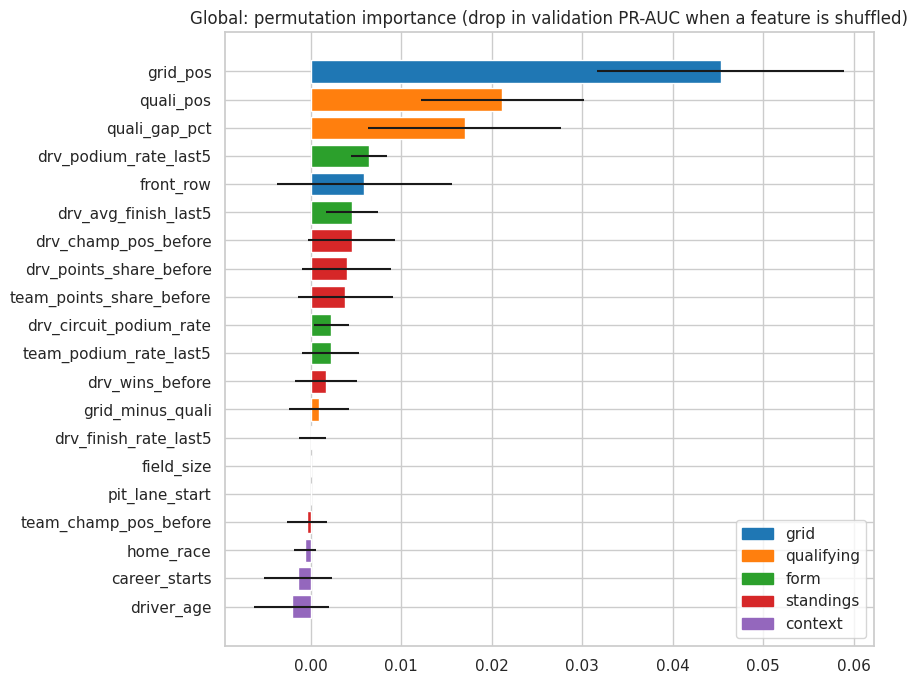

In [46]:
import shap, lime.lime_tabular                  # imported here, not at the top, to keep memory low

if BEST in hgb_models:
    xai_model = hgb_models[BEST]
elif BEST in rf_models:
    xai_model = rf_models[BEST]
else:
    xai_model = hgb_models[max(hgb_models, key=lambda m: val_rank[m])]
    print('Selected model is not tree-based; XAI uses the best gradient-boosting model, which is within', round(val_rank.max() - val_rank[max(hgb_models, key=lambda m: val_rank[m])], 4), 'val PR-AUC.')
xai_name = BEST if (BEST in hgb_models or BEST in rf_models) else max(hgb_models, key=lambda m: val_rank[m])
print('Explaining:', xai_name)

pi = permutation_importance(xai_model, X_val, y_val, scoring='average_precision', n_repeats=10, random_state=SEED, n_jobs=1)
pi_df = pd.DataFrame({'mean': pi.importances_mean, 'std': pi.importances_std}, index=FEATURES).sort_values('mean')
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(pi_df.index, pi_df['mean'], xerr=pi_df['std'], color=[palette[group_of[f]] for f in pi_df.index])
ax.set_title('Global: permutation importance (drop in validation PR-AUC when a feature is shuffled)')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()], labels=list(palette), loc='lower right')
plt.tight_layout(); plt.show()

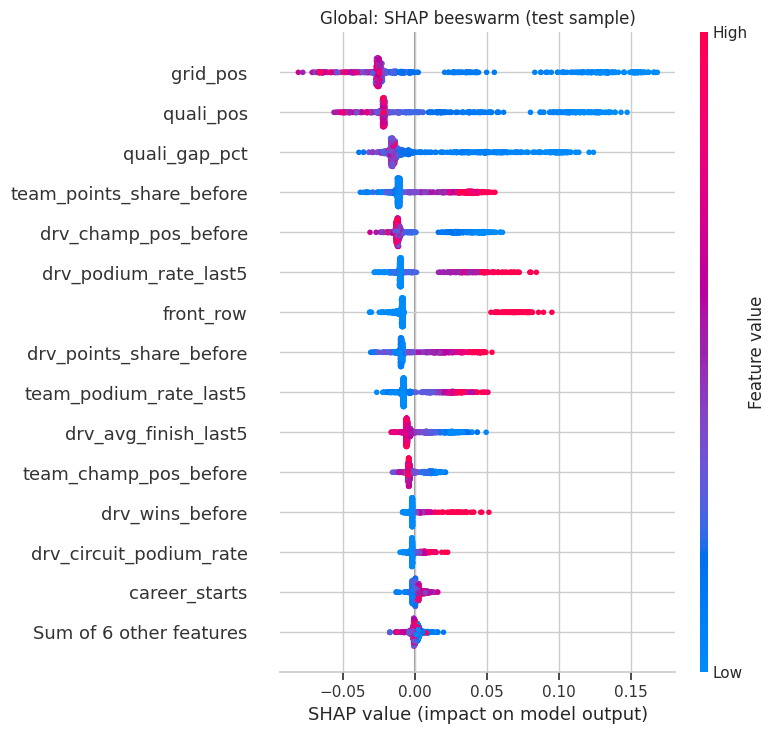

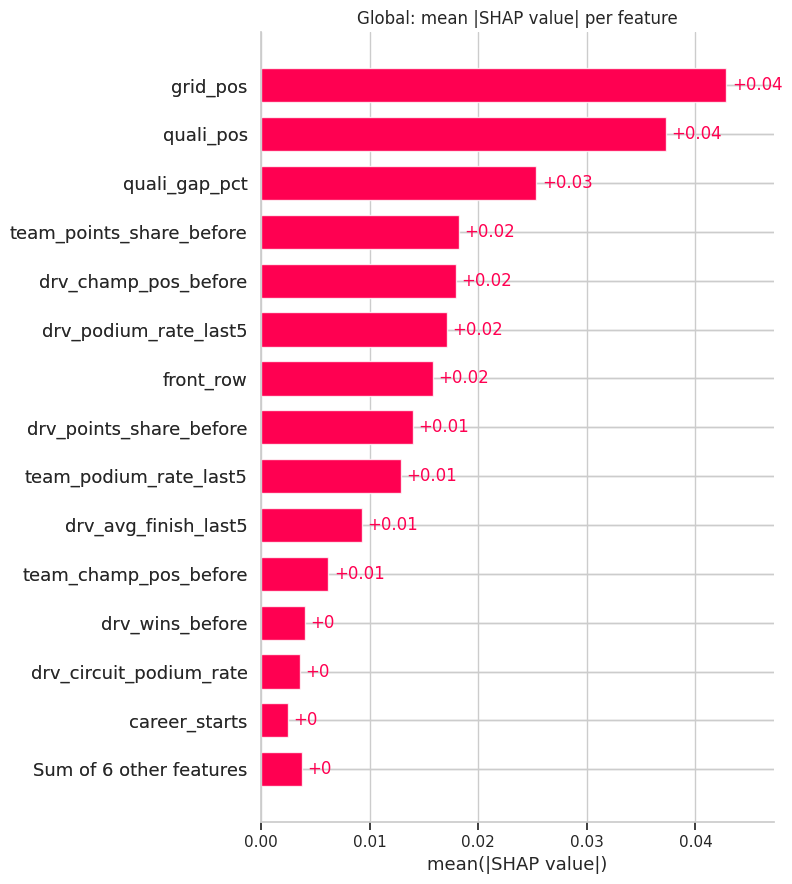

In [47]:
X_shap = X_test.sample(min(1000, len(X_test)), random_state=SEED)
tree_model = xai_model.named_steps['clf'] if isinstance(xai_model, Pipeline) else xai_model
X_shap_in = pd.DataFrame(xai_model.named_steps['impute'].transform(X_shap), columns=FEATURES, index=X_shap.index) if isinstance(xai_model, Pipeline) else X_shap
explainer = shap.TreeExplainer(tree_model)
sv = explainer(X_shap_in)
if sv.values.ndim == 3:                      # random forest returns one set of values per class -> keep "podium"
    sv = sv[:, :, 1]
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title('Global: SHAP beeswarm (test sample)'); plt.tight_layout(); plt.show()
shap.plots.bar(sv, max_display=15, show=False)
plt.title('Global: mean |SHAP value| per feature'); plt.tight_layout(); plt.show()

**Global interpretation.** Permutation importance asks "how much worse does the model get if this feature is scrambled?"; SHAP asks "how much does this feature push each prediction up or down?".
- Both put **`grid_pos`, `quali_pos` and `quali_gap_pct` on top**, followed by season-strength features (team points share, championship position) and recent form.
- Beeswarm direction: *low* grid / qualifying positions (blue = near the front) push **towards** a podium; a *small* pace gap to pole (blue) pushes towards a podium; *high* team points share and driver podium rate (red) push towards a podium; `front_row = 1` adds a clear extra push.
- Context features (`home_race`, `career_starts`, `driver_age`, `field_size`) have ≈ 0 permutation importance — consistent with the ablation and with Q2 (no home effect).
(For a random forest, SHAP values are in **probability** units: +0.05 = raises P(podium) by 5 points. For gradient boosting they would be log-odds.)

Max Verstappen (Red Bull), 2023 Belgian Grand Prix: grid 6, predicted P(podium) = 0.52, actual podium = 1


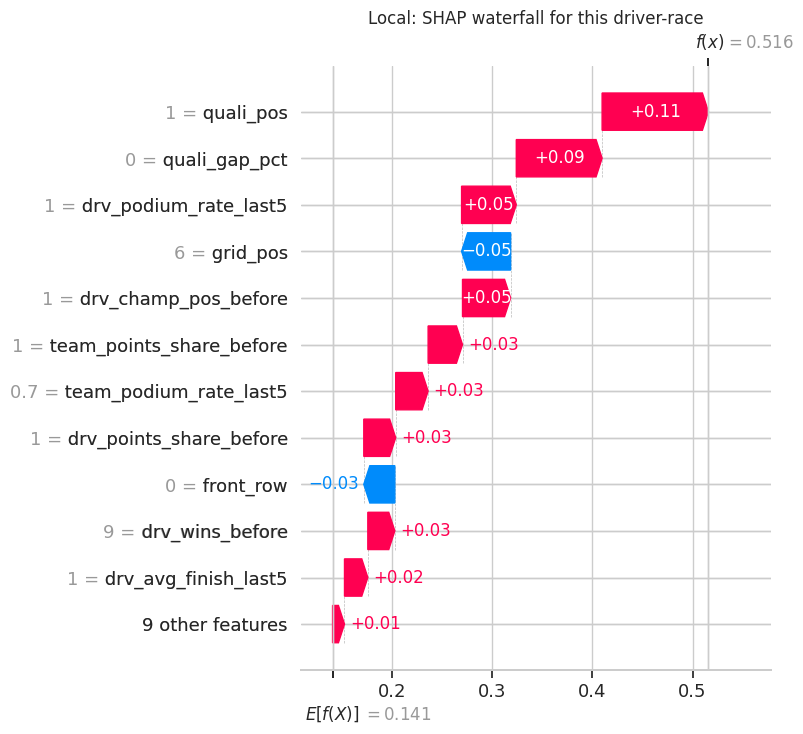

In [48]:
# Local explanation: an interesting test case — the most confident podium prediction for a driver NOT starting in the top 3
test_view = model_df[model_df.split == 'test'].copy()
test_view['p'] = xai_model.predict_proba(X_test)[:, 1]
cand = test_view[test_view['grid_pos'] > 3].sort_values('p', ascending=False).iloc[0]
row_idx = cand.name
print(f"{cand['forename']} {cand['surname']} ({cand['constructor_name']}), {cand['year']} {cand['race_name']}: "
      f"grid {int(cand['grid_pos'])}, predicted P(podium) = {cand['p']:.2f}, actual podium = {int(cand[TARGET])}")
if isinstance(xai_model, Pipeline):
    row_in = pd.DataFrame(xai_model.named_steps['impute'].transform(X_test.loc[[row_idx]]), columns=FEATURES, index=[row_idx])
else:
    row_in = X_test.loc[[row_idx]]
sv_row = explainer(row_in)
if sv_row.values.ndim == 3:
    sv_row = sv_row[:, :, 1]
shap.plots.waterfall(sv_row[0], max_display=12, show=False)
plt.title('Local: SHAP waterfall for this driver-race'); plt.tight_layout(); plt.show()

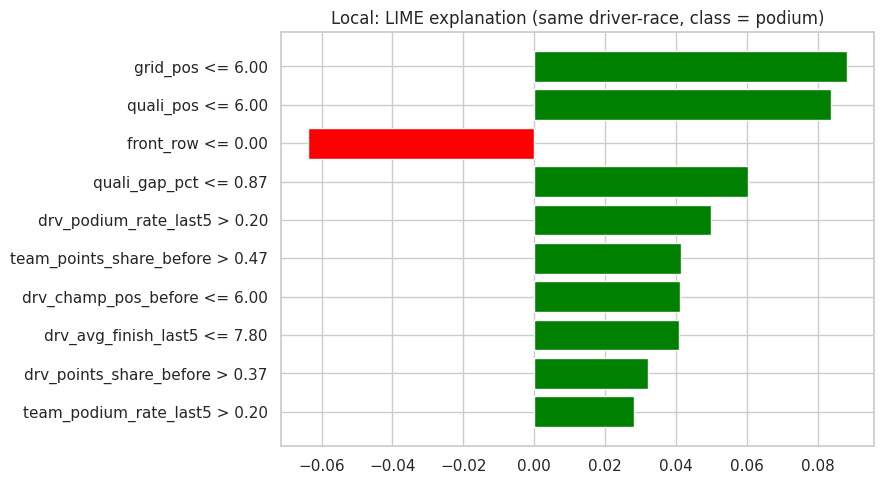

,condition,weight
0,grid_pos <= 6.00,0.088
1,quali_pos <= 6.00,0.084
2,front_row <= 0.00,-0.064
3,quali_gap_pct <= 0.87,0.060
4,drv_podium_rate_last5 > 0.20,0.050
5,team_points_share_before > 0.47,0.041
6,drv_champ_pos_before <= 6.00,0.041
7,drv_avg_finish_last5 <= 7.80,0.041
8,drv_points_share_before > 0.37,0.032
9,team_podium_rate_last5 > 0.20,0.028


In [49]:
lime_train = X_train.fillna(X_train.median())
lime_explainer = lime.lime_tabular.LimeTabularExplainer(lime_train.values, feature_names=FEATURES,
                                                        class_names=['no podium', 'podium'], discretize_continuous=True, random_state=SEED)
lime_row = X_test.loc[row_idx].fillna(X_train.median()).values
lime_exp = lime_explainer.explain_instance(lime_row, lambda a: xai_model.predict_proba(pd.DataFrame(a, columns=FEATURES)),
                                           num_features=10, labels=(1,))
fig = lime_exp.as_pyplot_figure(label=1); fig.set_size_inches(9, 5)
plt.title('Local: LIME explanation (same driver-race, class = podium)'); plt.tight_layout(); plt.show()
pd.DataFrame(lime_exp.as_list(label=1), columns=['condition', 'weight']).round(3)

**Local interpretation — Max Verstappen, 2023 Belgian GP.** He set the fastest qualifying time but took a 5-place grid penalty (gearbox) and started **6th**; he went on to win.
- **SHAP waterfall:** from the average P(podium) of 0.14, `quali_pos = 1` (+0.11) and `quali_gap_pct = 0` (+0.09) push strongly up, followed by his form, championship lead and team strength (+0.03 to +0.05 each). `grid_pos = 6` (−0.05) and `front_row = 0` (−0.03) pull down. Final P(podium) = **0.52**, above the 0.33 threshold → predicted podium (correct).
- **LIME** agrees on the story: `quali_pos <= 6`, `quali_gap_pct <= 0.87`, recent podium rate and points share push towards "podium", and `front_row <= 0` is the only clear push against.
- This is exactly the case the `qualifying` features were designed for: the grid alone (6th) would suggest ~18 % podium chance, but qualifying pace reveals the fastest car.
As stated above, these are reasons **the model** used — not causes of the result.

## 9. Inference function

`predict_podium(record)` takes a dictionary with the pre-race fields of one driver in one race and returns the podium probability.
- Missing fields are allowed: they become `NaN` and the model handles them (natively for gradient boosting, by imputation for the other pipelines).
- Unknown keys are reported, so typos are not silently ignored.
- The decision threshold is the one chosen on the **validation** set.

In [50]:
FINAL_MODEL = xai_model
FINAL_THRESHOLD = PROBS[xai_name]['thr']

def predict_podium(record, model=FINAL_MODEL, threshold=FINAL_THRESHOLD):
    unknown = sorted(set(record) - set(FEATURES))
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FEATURES}], dtype=float)
    missing = [f for f in FEATURES if pd.isna(row.at[0, f])]
    p = float(model.predict_proba(row)[:, 1][0])
    return {'podium_probability': round(p, 3), 'predicted_podium': bool(p >= threshold), 'threshold': round(threshold, 3),
            'missing_features': missing, 'ignored_unknown_keys': unknown}

complete_rows = model_df[(model_df.split == 'test') & model_df[FEATURES].notna().all(axis=1)]
example = complete_rows.iloc[0]
complete_record = example[FEATURES].to_dict()
print(f"Example: {example['forename']} {example['surname']}, {example['year']} {example['race_name']} (actual podium = {example[TARGET]})")
print('Complete record        ->', predict_podium(complete_record))

partial_record = {k: v for k, v in complete_record.items() if k not in FEATURE_GROUPS['qualifying'] + FEATURE_GROUPS['standings']}
partial_record['typo_feature'] = 1
print('Partially-missing      ->', predict_podium(partial_record))
pd.DataFrame({'complete record': pd.Series(complete_record), 'partially-missing record': pd.Series(partial_record).reindex(FEATURES)})

Example: Sergio Pérez, 2022 Saudi Arabian Grand Prix (actual podium = 0)
Complete record        -> {'podium_probability': 0.603, 'predicted_podium': True, 'threshold': 0.333, 'missing_features': [], 'ignored_unknown_keys': []}
Partially-missing      -> {'podium_probability': 0.251, 'predicted_podium': False, 'threshold': 0.333, 'missing_features': ['quali_pos', 'quali_gap_pct', 'grid_minus_quali', 'drv_champ_pos_before', 'drv_points_share_before', 'drv_wins_before', 'team_champ_pos_before', 'team_points_share_before'], 'ignored_unknown_keys': ['typo_feature']}


,complete record,partially-missing record
grid_pos,1.000000,1.000000
front_row,1.000000,1.000000
pit_lane_start,0.000000,0.000000
quali_pos,1.000000,NaN
quali_gap_pct,0.000000,NaN
grid_minus_quali,0.000000,NaN
drv_podium_rate_last5,0.000000,0.000000
drv_avg_finish_last5,11.600000,11.600000
drv_finish_rate_last5,0.400000,0.400000
team_podium_rate_last5,0.400000,0.400000


**Reading the demo.** With the complete record the model returns a probability close to its test-set behaviour. When the qualifying and standings fields are removed, the random-forest pipeline fills them with the **training medians** — i.e. it assumes an "average" driver for the missing parts — so the probability moves towards the average. The function therefore also returns `missing_features`, so a user knows how much of the prediction rests on filled-in values, and `ignored_unknown_keys`, so a typo such as `typo_feature` is not silently accepted.

## 10. Conclusions and limitations

**Summary**
- Cleaning: sentinels (`\N` and empty strings) → `NaN`; dates and times typed; 85 duplicated driver-race pairs (1950–1978 shared drives) resolved with a pre-race-only rule; all primary keys valid and all foreign keys reconcile.
- Modeling table: one row per (raceId, driverId), 2003–2024 (8,935 rows, 14.4 % podiums), 20 leakage-safe features in 5 groups; form uses only earlier races and standings come from the previous round.
- Models: grid-rule baseline, logistic regression, 3 random forests, 3 gradient-boosting variants and 2 shallow neural networks, compared on PR-AUC (primary), ROC-AUC, F1, precision and recall on train/validation/test with a temporal split. Selected: random forest (depth 6), test PR-AUC 0.709 vs 0.647 for the grid rule.
- Grid and qualifying dominate, season strength and form add to them; context features add nothing measurable (ablation, permutation importance and SHAP agree).
- Data-engineering answers: front-row conversion rankings shift between eras (ρ = 0.45); no home advantage after controlling for grid (OR 0.92, CI 0.78–1.08); mechanical retirements fell from 9.2 % to 6.0 % of starts.

**Known limitations**
- **Qualifying-coverage drift:** qualifying data is missing before 1994 and patchy until 2002 → the model only covers 2003–2024 and is not valid for older eras.
- **Era sensitivity:** regulations change the competitive order (2014 hybrid, 2022 ground effect); a model trained on 2003–2018 must generalize to a new era, and form features need a few races to catch up after big rule changes.
- **Missing context:** no weather, tyre strategy, car upgrades or driver transfers mid-season.
- **Scoring changes:** points systems changed (2003, 2010, 2019 fastest-lap point); we use points *share* of the leader to reduce this.
- **Home-country mapping** (Q2) uses nationality strings and maps mixed nationalities to one country; **mechanical classification** (Q3) excludes ambiguous statuses like "Retired".
- **Explanations are not causal** (Section 8).